# Credit Card Default Prediction: EDA, Visualization & Deep Learning
**Course:** U21ADP05 – Exploratory Data Analysis and Visualization | **Assignment II – Case Study**

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009) – 30,000 customers of a Taiwanese bank, 23 input features + 1 target (`default payment next month`).

**Real-world problem:** A bank must decide *which customers are likely to miss next month's payment* so it can set credit limits, trigger early-warning calls and reduce credit losses.

**Notebook map (follows the assignment's 7 steps and the 7 stages of visualization):**

| Visualization stage (Fry) | Where in this notebook |
|---|---|
| 1. Acquire | §1 Load data |
| 2. Parse | §1–2 Types, data dictionary |
| 3. Filter | §3 Cleaning (duplicates, invalid codes, outliers) |
| 4. Mine | §5–6 Statistics, distributions, tests |
| 5. Represent | §4–6 Charts chosen for each data type |
| 6. Refine | Titles, labels, colour and log-scales on every chart |
| 7. Interact | §7 Interactive Plotly chart (HTML) |


In [1]:
# ---------- Imports & global configuration ----------
import os, random, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import plotly.express as px

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")           # CPU: fully reproducible results for this small network

DATA_PATH = "../data/credit_default.csv"
FIG_DIR = "../figures"
REPORT_DIR = "../report"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(REPORT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
C_OK, C_DEF = "#2a9d8f", "#e76f51"          # colours: paid (teal) vs default (orange-red)

def save_fig(name):
    """Save the current matplotlib figure to ../figures (used in the report)."""
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

print("Device:", DEVICE)

Device: cpu


## 1. Dataset Selection & Loading (Acquire / Parse)

In [2]:
df_raw = pd.read_csv(DATA_PATH)
# Tidy names: the first payment-status column is called PAY_0 in the source (no PAY_1) -> rename for consistency
df = (df_raw.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})
            .drop(columns="ID"))                       # ID is just a row identifier, not a feature
print("Shape (rows, columns):", df.shape)
print("Input features:", df.shape[1] - 1, "| Target: DEFAULT (1 = defaulted next month)")
df.head()

Shape (rows, columns): (30000, 24)
Input features: 23 | Target: DEFAULT (1 = defaulted next month)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
dictionary = pd.DataFrame({
    "field": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": df.nunique().values,
    "meaning": [
        "Credit limit (NT$) incl. family supplementary credit",
        "Gender (1 = male, 2 = female)",
        "Education (1 grad school, 2 university, 3 high school, 4 other)",
        "Marital status (1 married, 2 single, 3 other)",
        "Age in years",
        "Repayment status Sep-2005 (-1 paid duly, 1..9 = months of delay)",
        "Repayment status Aug-2005", "Repayment status Jul-2005", "Repayment status Jun-2005",
        "Repayment status May-2005", "Repayment status Apr-2005",
        "Bill statement Sep-2005 (NT$)", "Bill statement Aug-2005", "Bill statement Jul-2005",
        "Bill statement Jun-2005", "Bill statement May-2005", "Bill statement Apr-2005",
        "Amount paid Sep-2005 (NT$)", "Amount paid Aug-2005", "Amount paid Jul-2005",
        "Amount paid Jun-2005", "Amount paid May-2005", "Amount paid Apr-2005",
        "TARGET: 1 = default next month, 0 = pays"]})
dictionary

,field,dtype,n_unique,meaning
0,LIMIT_BAL,int64,81,Credit limit (NT$) incl. family supplementary ...
1,SEX,int64,2,"Gender (1 = male, 2 = female)"
2,EDUCATION,int64,7,"Education (1 grad school, 2 university, 3 high..."
3,MARRIAGE,int64,4,"Marital status (1 married, 2 single, 3 other)"
4,AGE,int64,56,Age in years
5,PAY_1,int64,11,"Repayment status Sep-2005 (-1 paid duly, 1..9 ..."
6,PAY_2,int64,11,Repayment status Aug-2005
7,PAY_3,int64,11,Repayment status Jul-2005
8,PAY_4,int64,11,Repayment status Jun-2005
9,PAY_5,int64,10,Repayment status May-2005


## 2. Data Understanding

In [4]:
summary = df.describe().T
summary["skew"] = df.skew()
summary["kurtosis"] = df.kurtosis()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,0.99,0.54
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0,-0.42,-1.82
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0,0.97,2.08
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0,-0.02,-1.36
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,0.73,0.04
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0,0.73,2.72
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0,0.79,1.57
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0,0.84,2.08
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0,1.00,3.50
PAY_5,30000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0,1.01,3.99


In [5]:
vc = df["DEFAULT"].value_counts()
print(vc.to_string()); print(f"\nDefault rate: {df['DEFAULT'].mean():.2%}")

DEFAULT
0    23364
1     6636

Default rate: 22.12%


## 3. Data Cleaning & Transformation (Filter)
Checks performed: missing values, duplicates, invalid category codes, outliers, then feature engineering.

In [6]:
print("Missing values per column (total):", int(df.isna().sum().sum()))
dups = df.duplicated().sum()
print("Duplicate rows (ID already removed):", dups)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Missing values per column (total): 0
Duplicate rows (ID already removed): 35
Shape after removing duplicates: (29965, 24)


**Finding:** the dataset has **no missing values**, so no imputation was needed (the real cleaning problems are hidden elsewhere - see below). **35 exact duplicate rows** were found once the ID column was dropped and removed, leaving **29,965 customers**.

In [7]:
# Some category codes are undocumented in the data dictionary (EDUCATION 0,5,6 ; MARRIAGE 0) -> merge into "other"
print("EDUCATION before:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE  before:", df["MARRIAGE"].value_counts().sort_index().to_dict())
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print("EDUCATION after :", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE  after :", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("\nPAY_x values seen:", sorted(df["PAY_1"].unique()),
      "(-2 = no consumption, -1 = paid duly, 0 = revolving credit, 1-8 = months late)")

EDUCATION before: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE  before: {0: 54, 1: 13643, 2: 15945, 3: 323}
EDUCATION after : {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE  after : {1: 13643, 2: 15945, 3: 377}

PAY_x values seen: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] (-2 = no consumption, -1 = paid duly, 0 = revolving credit, 1-8 = months late)


**Finding:** `EDUCATION` contains the undocumented codes 0, 5 and 6 (345 rows) and `MARRIAGE` contains 0 (54 rows). These are not in the data dictionary, so they were merged into the existing *Other* category. `PAY_x` also contains the undocumented values -2 and 0, which are kept because they are frequent and behave like real states (no consumption / revolving credit).

In [8]:
# Outlier detection with the 1.5*IQR rule on the money columns
money = [c for c in df.columns if c.startswith(("BILL_AMT", "PAY_AMT"))] + ["LIMIT_BAL"]
rows = []
for c in money:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n, 100 * n / len(df), df[c].skew()))
outlier_tbl = pd.DataFrame(rows, columns=["column", "n_outliers", "pct_outliers", "skew"]).round(2)
print("Rows are NOT dropped: large balances/limits are genuine customers. They are tamed by a signed log transform later.")
outlier_tbl

Rows are NOT dropped: large balances/limits are genuine customers. They are tamed by a signed log transform later.


,column,n_outliers,pct_outliers,skew
0,BILL_AMT1,2386,7.96,2.66
1,BILL_AMT2,2390,7.98,2.70
2,BILL_AMT3,2469,8.24,3.09
3,BILL_AMT4,2616,8.73,2.82
4,BILL_AMT5,2724,9.09,2.87
5,BILL_AMT6,2688,8.97,2.85
6,PAY_AMT1,2742,9.15,14.66
7,PAY_AMT2,2723,9.09,30.44
8,PAY_AMT3,2596,8.66,17.21
9,PAY_AMT4,2993,9.99,12.90


**Finding:** every bill and payment column has roughly **8-10 % IQR outliers** and extreme skew (PAY_AMT columns up to 30). These are genuine high-value customers, not data errors, so they are **kept** and handled with a signed-log transform in the preprocessing step. Deleting them would remove exactly the customers a bank cares about.

In [9]:
# ---------- Feature engineering (domain-driven) ----------
bill = [f"BILL_AMT{i}" for i in range(1, 7)]; pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_st = [f"PAY_{i}" for i in range(1, 7)]
df["AVG_BILL"] = df[bill].mean(axis=1)                                    # typical monthly balance
df["AVG_PAY_AMT"] = df[pay_amt].mean(axis=1)                              # typical monthly repayment
df["UTILIZATION"] = (df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-1, 3)       # how much of the limit is used
df["PAY_RATIO"] = (df[pay_amt].sum(axis=1) / df[bill[:5]].clip(lower=1).sum(axis=1)).clip(0, 3)  # repaid / billed
df["N_DELAY"] = (df[pay_st] > 0).sum(axis=1)                              # months (of 6) paid late
df["MAX_DELAY"] = df[pay_st].max(axis=1)                                  # worst delay
print("Engineered 6 new features ->", df.shape[1] - 1, "input features now")
df[["AVG_BILL", "AVG_PAY_AMT", "UTILIZATION", "PAY_RATIO", "N_DELAY", "MAX_DELAY"]].describe().round(2)

Engineered 6 new features -> 29 input features now


,AVG_BILL,AVG_PAY_AMT,UTILIZATION,PAY_RATIO,N_DELAY,MAX_DELAY
count,29965.00,29965.00,29965.00,29965.00,29965.00,29965.00
mean,45029.33,5281.30,0.42,0.46,0.83,0.44
std,63279.07,10142.31,0.41,0.66,1.55,1.34
min,-56043.17,0.00,-0.62,0.00,0.00,-2.00
25%,4841.00,1116.67,0.02,0.05,0.00,0.00
50%,21110.83,2400.00,0.32,0.10,0.00,0.00
75%,57166.17,5600.00,0.83,0.71,1.00,2.00
max,877313.83,627344.33,3.00,3.00,6.00,8.00


**Why these features:** credit-risk practice looks at *how much of the limit is used* (UTILIZATION), *how much of the bill is actually repaid* (PAY_RATIO) and *how often/how badly the customer was late* (N_DELAY, MAX_DELAY). They compress six months of columns into a few behavioural signals.

In [10]:
# Human-readable labels, used only for plotting
SEX_L = {1: "Male", 2: "Female"}
EDU_L = {1: "Grad school", 2: "University", 3: "High school", 4: "Other"}
MAR_L = {1: "Married", 2: "Single", 3: "Other"}
vis = df.copy()
vis["Status"] = vis["DEFAULT"].map({0: "Paid", 1: "Default"})
PAL = {"Paid": C_OK, "Default": C_DEF}

## 4. Univariate Analysis (Represent)

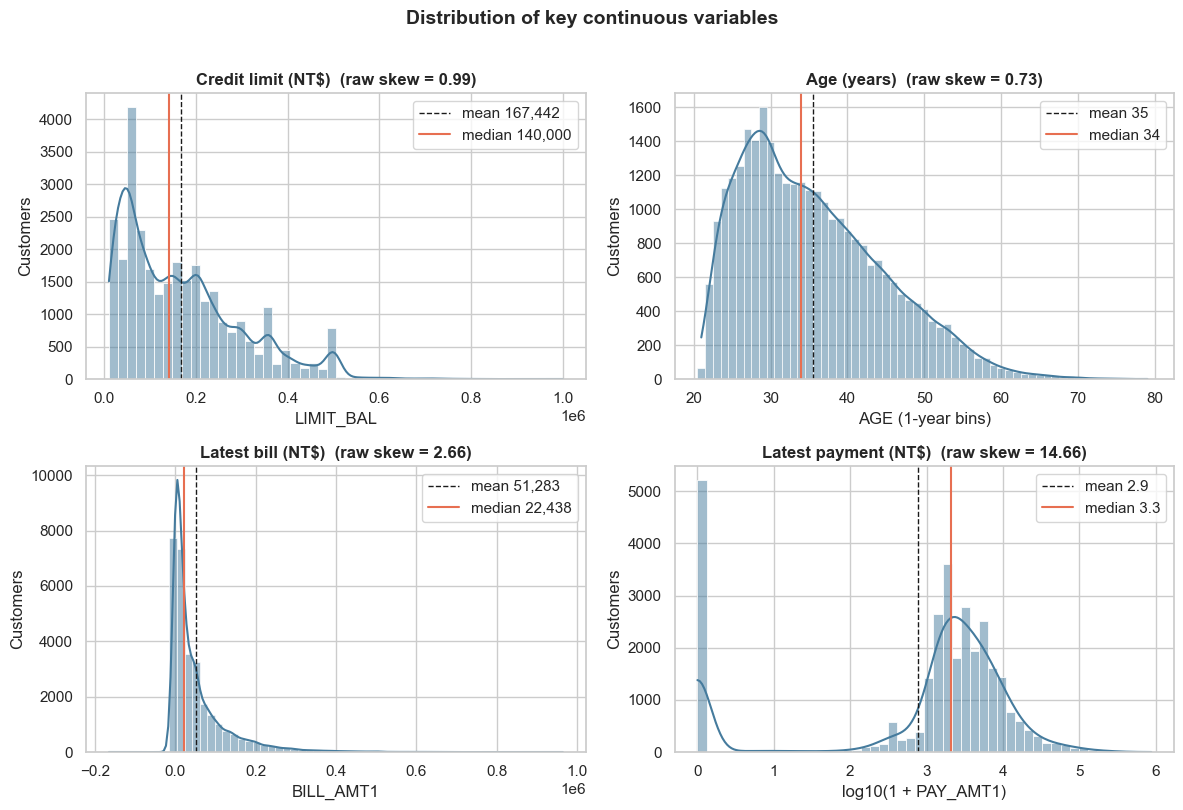

In [11]:
# VIS 1 - Histograms + KDE of the key continuous variables
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
panels = [("LIMIT_BAL", "Credit limit (NT$)", df["LIMIT_BAL"], 50, "LIMIT_BAL"),
          ("AGE", "Age (years)", df["AGE"], np.arange(20.5, 80, 1), "AGE (1-year bins)"),
          ("BILL_AMT1", "Latest bill (NT$)", df["BILL_AMT1"], 60, "BILL_AMT1"),
          ("PAY_AMT1", "Latest payment (NT$)", df["PAY_AMT1"], 50, "PAY_AMT1")]
for a, (col, title, x, bins, xl) in zip(ax.ravel(), panels):
    sk = x.skew()
    if col == "PAY_AMT1":                          # raw scale is unreadable (skew > 14): show log10(1 + payment)
        x = np.log10(1 + x); xl = "log10(1 + PAY_AMT1)"
    sns.histplot(x, kde=True, bins=bins, color="#457b9d", ax=a)
    a.axvline(x.mean(), color="k", ls="--", lw=1, label=f"mean {x.mean():,.1f}" if col == "PAY_AMT1" else f"mean {x.mean():,.0f}")
    a.axvline(x.median(), color=C_DEF, ls="-", lw=1.5, label=f"median {x.median():,.1f}" if col == "PAY_AMT1" else f"median {x.median():,.0f}")
    a.set(title=f"{title}  (raw skew = {sk:.2f})", xlabel=xl, ylabel="Customers"); a.legend()
plt.suptitle("Distribution of key continuous variables", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); save_fig("01_histograms"); plt.show()

**What it shows:** Distribution (histogram + KDE) of credit limit, age, latest bill and latest payment, with mean (dashed) and median (solid) lines.

**Why I created it:** To see the shape, centre and skew of each continuous variable before choosing transformations.

**Insights:**
- All four variables are **right-skewed**: mean (167,442) > median (140,000) for the credit limit, and mean 51,283 > median 22,438 for the bill. The payment is so skewed (raw skew 14.7) that it is drawn on a log10 scale; its raw median is only NT$2,102 against a mean of 5,670.
- Credit limits cluster on round numbers (a spike near NT$50,000 and a smaller one at NT$500,000), so they behave like a discrete, 'bucketed' variable.
- Most customers are young: the bulk of the age distribution lies between 25 and 45 (median 34).
- Heavy skew means linear/neural models would be dominated by a few huge values -> log transform + standardization is justified.

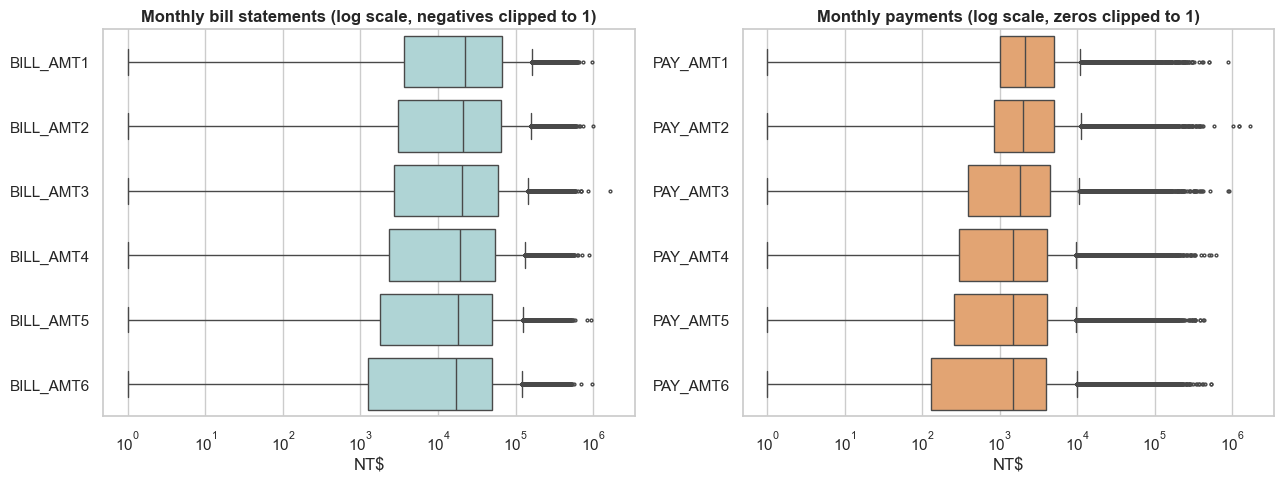

In [12]:
# VIS 2 - Boxplots of the money columns (log scale so the heavy tails stay readable)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df[bill].clip(lower=1), orient="h", color="#a8dadc", fliersize=2, ax=ax[0])
ax[0].set(xscale="log", title="Monthly bill statements (log scale, negatives clipped to 1)", xlabel="NT$")
sns.boxplot(data=df[pay_amt].clip(lower=1), orient="h", color="#f4a261", fliersize=2, ax=ax[1])
ax[1].set(xscale="log", title="Monthly payments (log scale, zeros clipped to 1)", xlabel="NT$")
plt.tight_layout(); save_fig("02_boxplots_money"); plt.show()

**What it shows:** Boxplots (log scale) of the six monthly bill statements and six monthly payments.

**Why I created it:** To compare spread and detect outliers across months and to confirm that the problem is the same in every month.

**Insights:**
- The six months look almost identical: median bill about NT$17-22k, median payment about NT$1.5-2.1k - a customer typically repays roughly a tenth of the bill.
- A dense cloud of high outliers (8-10 % of rows) appears on every month; payments reach NT$1-1.7 million.
- Bills can be negative (customer overpaid), which is why a *signed* log transform is used later.
- The payment boxes extend far down to ~NT$0: many customers pay nothing in a given month.

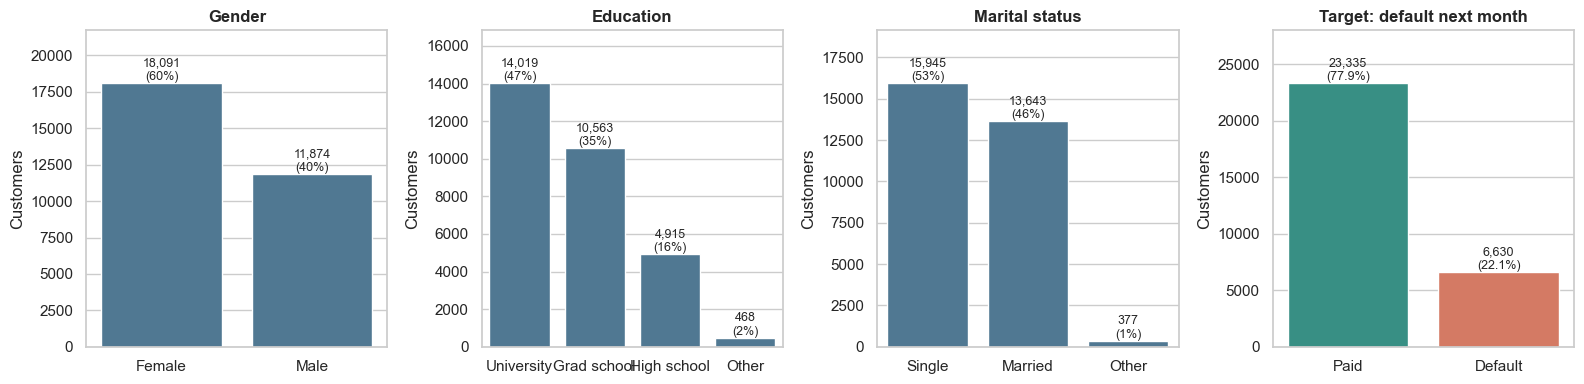

In [13]:
# VIS 3 - Bar charts of the categorical variables and the target
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (col, lab, t) in zip(ax[:3], [("SEX", SEX_L, "Gender"), ("EDUCATION", EDU_L, "Education"), ("MARRIAGE", MAR_L, "Marital status")]):
    s = df[col].map(lab).value_counts()
    sns.barplot(x=s.index, y=s.values, color="#457b9d", ax=a)
    for i, v in enumerate(s.values): a.text(i, v, f"{v:,}\n({v/len(df):.0%})", ha="center", va="bottom", fontsize=9)
    a.set(title=t, xlabel="", ylabel="Customers"); a.set_ylim(0, s.max() * 1.2)
s = vis["Status"].value_counts()
sns.barplot(x=s.index, y=s.values, palette=PAL, ax=ax[3])
for i, v in enumerate(s.values): ax[3].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax[3].set(title="Target: default next month", xlabel="", ylabel="Customers"); ax[3].set_ylim(0, s.max() * 1.2)
plt.tight_layout(); save_fig("03_categorical_counts"); plt.show()

**What it shows:** Bar charts with counts and percentages for gender, education, marital status and the target.

**Why I created it:** To check category balance and whether the target is imbalanced (this decides the metrics to use).

**Insights:**
- Roughly 60 % of customers are women; university (47 %) and graduate school (35 %) dominate education; about 53 % are single.
- The target is **imbalanced: only 22.1 % defaulted**. A model that always predicts 'pays' would already be 77.9 % accurate, so accuracy alone is misleading and we also use AUC, precision, recall and F1.

## 5. Probability Distributions (Mine)
We fit **continuous** distributions to AGE and LIMIT_BAL and **discrete** distributions to the number of late months, then test the goodness of fit (Kolmogorov–Smirnov test, AIC).

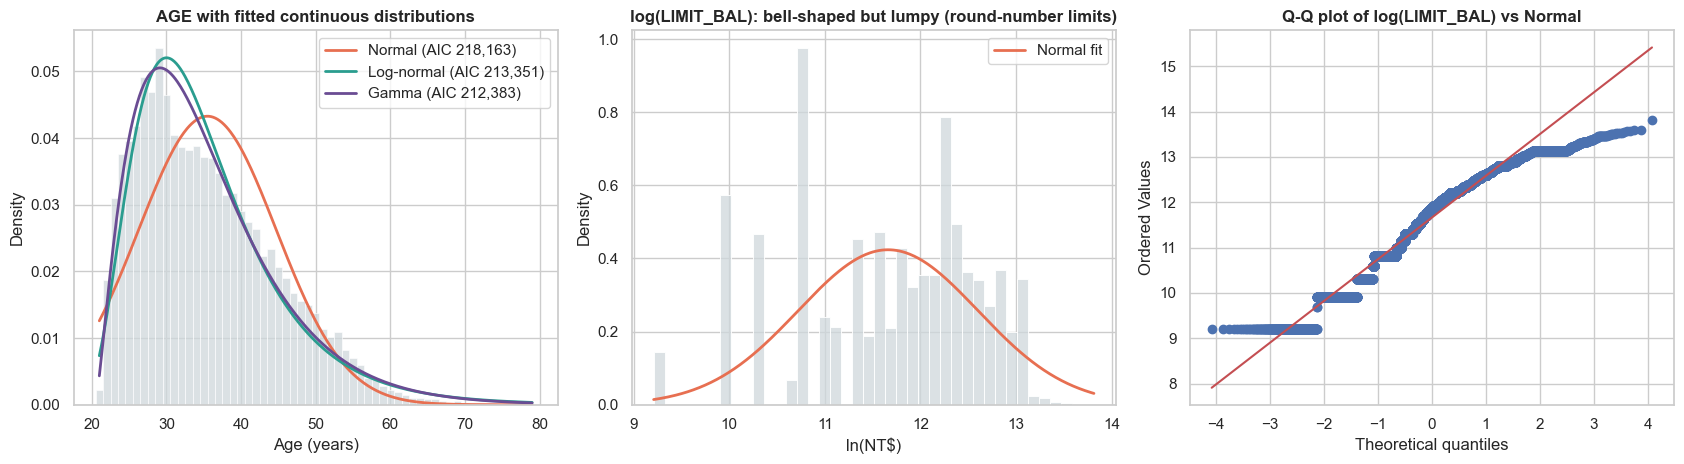

distribution  AIC (lower=better)  KS statistic (lower=better)
      Normal            218163.5                       0.0943
  Log-normal            213351.2                       0.0509
       Gamma            212382.8                       0.0461

AGE: skew=0.73; log(LIMIT_BAL): skew=-0.51, raw LIMIT_BAL skew=0.99


In [14]:
# VIS 4 - Continuous distribution fitting (AGE) + lognormality check (LIMIT_BAL)
age = df["AGE"].values.astype(float)
fits = {"Normal": stats.norm, "Log-normal": stats.lognorm, "Gamma": stats.gamma}
rows = []
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(age, stat="density", bins=np.arange(20.5, 80, 1), color="#cfd8dc", ax=ax[0])
xs = np.linspace(age.min(), age.max(), 400)
for (name, dist), c in zip(fits.items(), ["#e76f51", "#2a9d8f", "#6a4c93"]):
    p = dist.fit(age)
    ll = dist.logpdf(age, *p).sum(); aic = 2 * len(p) - 2 * ll
    ks = stats.kstest(age, dist.cdf, args=p)
    rows.append((name, round(aic, 1), round(ks.statistic, 4)))
    ax[0].plot(xs, dist.pdf(xs, *p), color=c, lw=2, label=f"{name} (AIC {aic:,.0f})")
ax[0].set(title="AGE with fitted continuous distributions", xlabel="Age (years)", ylabel="Density"); ax[0].legend()
fit_tbl = pd.DataFrame(rows, columns=["distribution", "AIC (lower=better)", "KS statistic (lower=better)"])
lb = np.log(df["LIMIT_BAL"].values.astype(float))
sns.histplot(lb, stat="density", bins=40, color="#cfd8dc", ax=ax[1])
xs2 = np.linspace(lb.min(), lb.max(), 300)
ax[1].plot(xs2, stats.norm.pdf(xs2, lb.mean(), lb.std()), color="#e76f51", lw=2, label="Normal fit")
ax[1].set(title="log(LIMIT_BAL): bell-shaped but lumpy (round-number limits)", xlabel="ln(NT$)", ylabel="Density"); ax[1].legend()
stats.probplot(lb, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q plot of log(LIMIT_BAL) vs Normal")
plt.tight_layout(); save_fig("04_continuous_distributions"); plt.show()
print(fit_tbl.to_string(index=False))
print(f"\nAGE: skew={stats.skew(age):.2f}; log(LIMIT_BAL): skew={stats.skew(lb):.2f}, raw LIMIT_BAL skew={df['LIMIT_BAL'].skew():.2f}")

**What it shows:** Left: AGE with fitted Normal, Log-normal and Gamma curves. Middle/right: histogram and Q-Q plot of log(LIMIT_BAL) against a Normal distribution.

**Why I created it:** To identify the *continuous probability distribution* each variable follows (CO4) and test it with AIC and the KS statistic.

**Insights:**
- **Gamma is the best fit for AGE** (lowest AIC 212,383 and KS 0.046), then Log-normal (AIC 213,351, KS 0.051); the **Normal fit is clearly worst** (AIC 218,163, KS 0.094) because age is right-skewed (skew 0.73) and bounded below at 21.
- Taking the log of LIMIT_BAL reduces the skew from +0.99 to -0.51 and gives a roughly bell-shaped histogram, so a log-normal is a reasonable *first approximation*.
- The Q-Q plot shows the approximation is **not perfect**: a hard floor at NT$10,000 and a cluster at the top (round-number limits) bend both tails away from the line. With 30,000 rows any formal test would reject exact normality, so we describe it as 'approximately log-normal'.

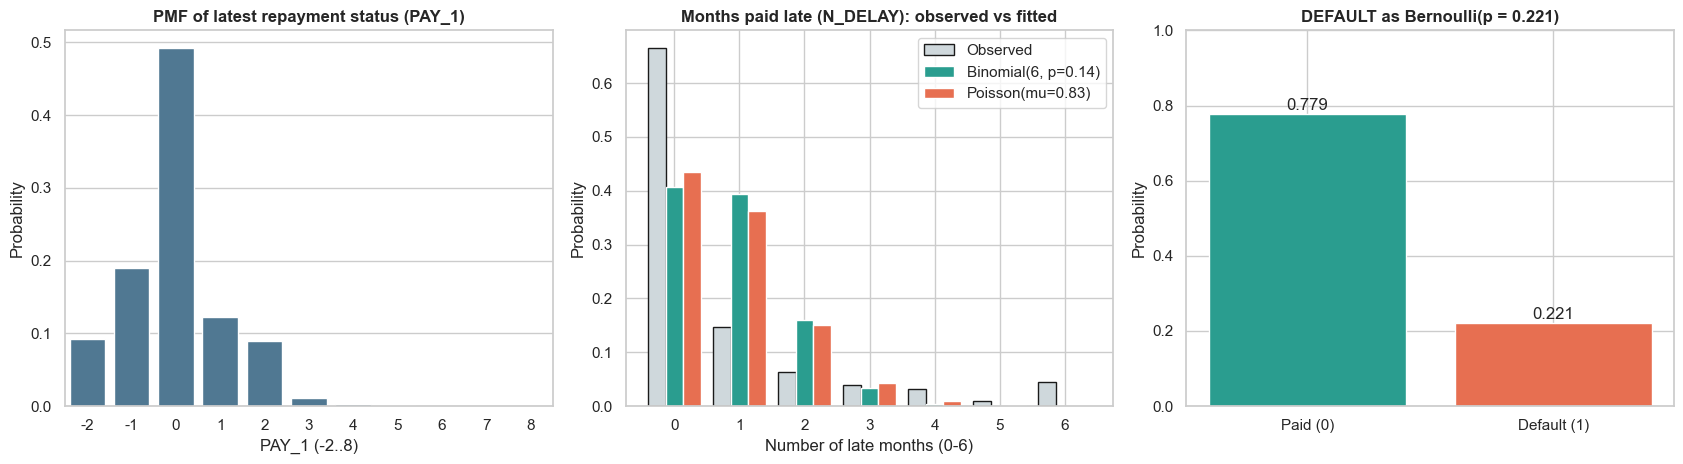

N_DELAY mean = 0.834, variance = 2.417  (variance/mean = 2.90; Binomial expects 0.86, Poisson expects 1.00)
Total-variation distance: Binomial = 0.344, Poisson = 0.306  (smaller = better fit)


In [15]:
# VIS 5 - Discrete distributions: PAY_1 (ordinal PMF), N_DELAY vs Binomial/Poisson, DEFAULT as Bernoulli
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
pmf = df["PAY_1"].value_counts(normalize=True).sort_index()
sns.barplot(x=pmf.index, y=pmf.values, color="#457b9d", ax=ax[0])
ax[0].set(title="PMF of latest repayment status (PAY_1)", xlabel="PAY_1 (-2..8)", ylabel="Probability")
k = np.arange(0, 7); obs = df["N_DELAY"].value_counts(normalize=True).reindex(k, fill_value=0).values
m, v = df["N_DELAY"].mean(), df["N_DELAY"].var()
binom_pmf = stats.binom.pmf(k, 6, m / 6); pois_pmf = stats.poisson.pmf(k, m)
w = 0.27
ax[1].bar(k - w, obs, w, label="Observed", color="#cfd8dc", edgecolor="k")
ax[1].bar(k, binom_pmf, w, label=f"Binomial(6, p={m/6:.2f})", color="#2a9d8f")
ax[1].bar(k + w, pois_pmf, w, label=f"Poisson(mu={m:.2f})", color="#e76f51")
ax[1].set(title="Months paid late (N_DELAY): observed vs fitted", xlabel="Number of late months (0-6)", ylabel="Probability"); ax[1].legend()
p = df["DEFAULT"].mean()
ax[2].bar(["Paid (0)", "Default (1)"], [1 - p, p], color=[C_OK, C_DEF])
ax[2].set(title=f"DEFAULT as Bernoulli(p = {p:.3f})", ylabel="Probability"); ax[2].set_ylim(0, 1)
for i, val in enumerate([1 - p, p]): ax[2].text(i, val + 0.01, f"{val:.3f}", ha="center")
plt.tight_layout(); save_fig("05_discrete_distributions"); plt.show()
tv_b = 0.5 * np.abs(obs - binom_pmf).sum(); tv_p = 0.5 * np.abs(obs - pois_pmf).sum()
print(f"N_DELAY mean = {m:.3f}, variance = {v:.3f}  (variance/mean = {v/m:.2f}; Binomial expects {1-m/6:.2f}, Poisson expects 1.00)")
print(f"Total-variation distance: Binomial = {tv_b:.3f}, Poisson = {tv_p:.3f}  (smaller = better fit)")

**What it shows:** Left: probability mass function of the latest repayment status (PAY_1). Middle: observed number of late months (N_DELAY) vs fitted Binomial and Poisson. Right: the target as a Bernoulli variable.

**Why I created it:** To study the *discrete* distributions in the data (CO4) and check whether textbook models describe them.

**Insights:**
- PAY_1 is dominated by 0 (revolving credit, ~49 %), followed by -1 (paid duly, ~19 %), 1 (~12 %), -2 (~9 %) and 2 (~9 %); delays of 3+ months are rare (~1.5 %).
- N_DELAY has mean 0.83 but variance 2.42 (**variance/mean = 2.9**). Binomial would predict 0.86 and Poisson 1.0, so the data is **strongly over-dispersed**; neither model fits (total-variation distance 0.344 Binomial, 0.306 Poisson).
- Why: about two thirds of customers are never late (67 %), while ~4.5 % were late in all six months. The population is a *mixture of two behaviours* (reliable payers vs chronic late payers), which a single Binomial/Poisson cannot represent.
- DEFAULT is Bernoulli with p = 0.221.

## 6. Bivariate & Multivariate Analysis (Mine / Represent)

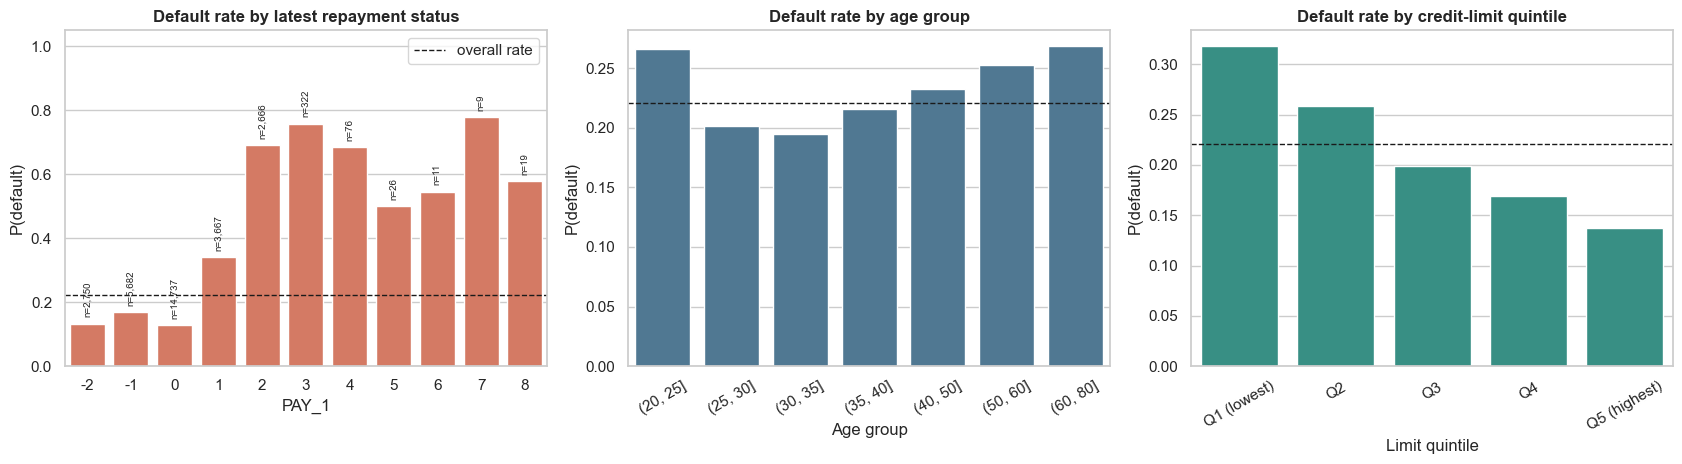

In [16]:
# VIS 6 - Default rate vs the strongest candidate drivers
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
r = df.groupby("PAY_1")["DEFAULT"].agg(["mean", "size"])
sns.barplot(x=r.index, y=r["mean"], color="#e76f51", ax=ax[0])
for i, (m_, n_) in enumerate(zip(r["mean"], r["size"])): ax[0].text(i, m_ + 0.02, f"n={n_:,}", ha="center", fontsize=7, rotation=90, va="bottom")
ax[0].axhline(df["DEFAULT"].mean(), color="k", ls="--", lw=1, label="overall rate"); ax[0].legend()
ax[0].set(title="Default rate by latest repayment status", xlabel="PAY_1", ylabel="P(default)"); ax[0].set_ylim(0, 1.05)
df["AGE_GRP"] = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 50, 60, 80])
r2 = df.groupby("AGE_GRP")["DEFAULT"].mean()
sns.barplot(x=r2.index.astype(str), y=r2.values, color="#457b9d", ax=ax[1])
ax[1].axhline(df["DEFAULT"].mean(), color="k", ls="--", lw=1)
ax[1].set(title="Default rate by age group", xlabel="Age group", ylabel="P(default)")
df["LIMIT_Q"] = pd.qcut(df["LIMIT_BAL"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
r3 = df.groupby("LIMIT_Q")["DEFAULT"].mean()
sns.barplot(x=r3.index.astype(str), y=r3.values, color="#2a9d8f", ax=ax[2])
ax[2].axhline(df["DEFAULT"].mean(), color="k", ls="--", lw=1)
ax[2].set(title="Default rate by credit-limit quintile", xlabel="Limit quintile", ylabel="P(default)")
for a in ax[1:]: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig("06_default_rate_drivers"); plt.show()

**What it shows:** Default probability for each repayment-status value, each age group and each credit-limit quintile (dashed line = overall 22.1 %).

**Why I created it:** Bivariate analysis of the three most promising drivers against the target.

**Insights:**
- **Repayment status is by far the strongest driver:** customers who paid on time or used revolving credit (PAY_1 <= 0) default 13-17 % of the time, those one month late 34 %, two months late 69 % and three months late 76 %.
- **Higher credit limit -> lower default**: 31.7 % in the lowest limit quintile falling to 13.7 % in the highest (banks give high limits to reliable customers).
- Age has a **U-shape**: the youngest (20-25, 26.7 %) and oldest (60+, 26.8 %) default most, ages 30-35 least (19.4 %).
- Small groups (n shown above bars, e.g. PAY_1 = 5-8) give noisy rates, so conclusions are drawn mainly from groups with hundreds of customers.

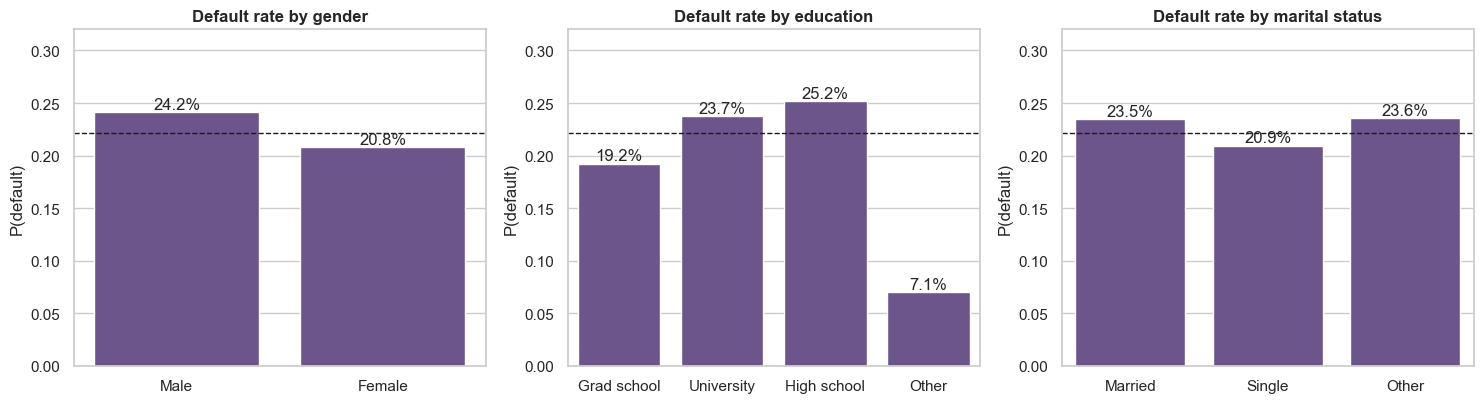

,variable,chi2,dof,p-value,Cramer's V
0,SEX,47.1,1,6.64e-12,0.040
1,EDUCATION,160.5,3,1.46e-34,0.073
2,MARRIAGE,27.5,2,1.07e-06,0.030


In [17]:
# VIS 7 - Default rate by categorical groups
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (col, lab, t) in zip(ax, [("SEX", SEX_L, "Gender"), ("EDUCATION", EDU_L, "Education"), ("MARRIAGE", MAR_L, "Marital status")]):
    rr = df.groupby(col)["DEFAULT"].mean().rename(index=lab)
    sns.barplot(x=rr.index, y=rr.values, color="#6a4c93", ax=a)
    a.axhline(df["DEFAULT"].mean(), color="k", ls="--", lw=1)
    for i, v_ in enumerate(rr.values): a.text(i, v_ + 0.003, f"{v_:.1%}", ha="center")
    a.set(title=f"Default rate by {t.lower()}", xlabel="", ylabel="P(default)"); a.set_ylim(0, 0.32)
plt.tight_layout(); save_fig("07_default_rate_categorical"); plt.show()
# Chi-square test of independence + Cramer's V
rows = []
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    ct = pd.crosstab(df[col], df["DEFAULT"]); chi2, pv, dof, _ = stats.chi2_contingency(ct)
    rows.append((col, round(chi2, 1), dof, f"{pv:.2e}", round(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), 3)))
chi_tbl = pd.DataFrame(rows, columns=["variable", "chi2", "dof", "p-value", "Cramer's V"]); chi_tbl

**What it shows:** Default rate by gender, education and marital status, plus chi-square tests of independence with Cramer's V (effect size).

**Why I created it:** To test whether demographic variables are associated with default.

**Insights:**
- Differences are small: men 24.2 % vs women 20.8 %; high school 25.2 %, university 23.7 %, graduate school 19.2 %; single 20.9 % vs married 23.5 %.
- All three chi-square tests are *statistically* significant (p < 1e-5) because n is large, but **Cramer's V is tiny (0.03-0.07)**, so the practical effect is weak. Education has the largest effect (V = 0.073).
- The 'Other' education bar (7.1 %) is mostly the merged undocumented codes and is a data-quality artefact, not a real group.

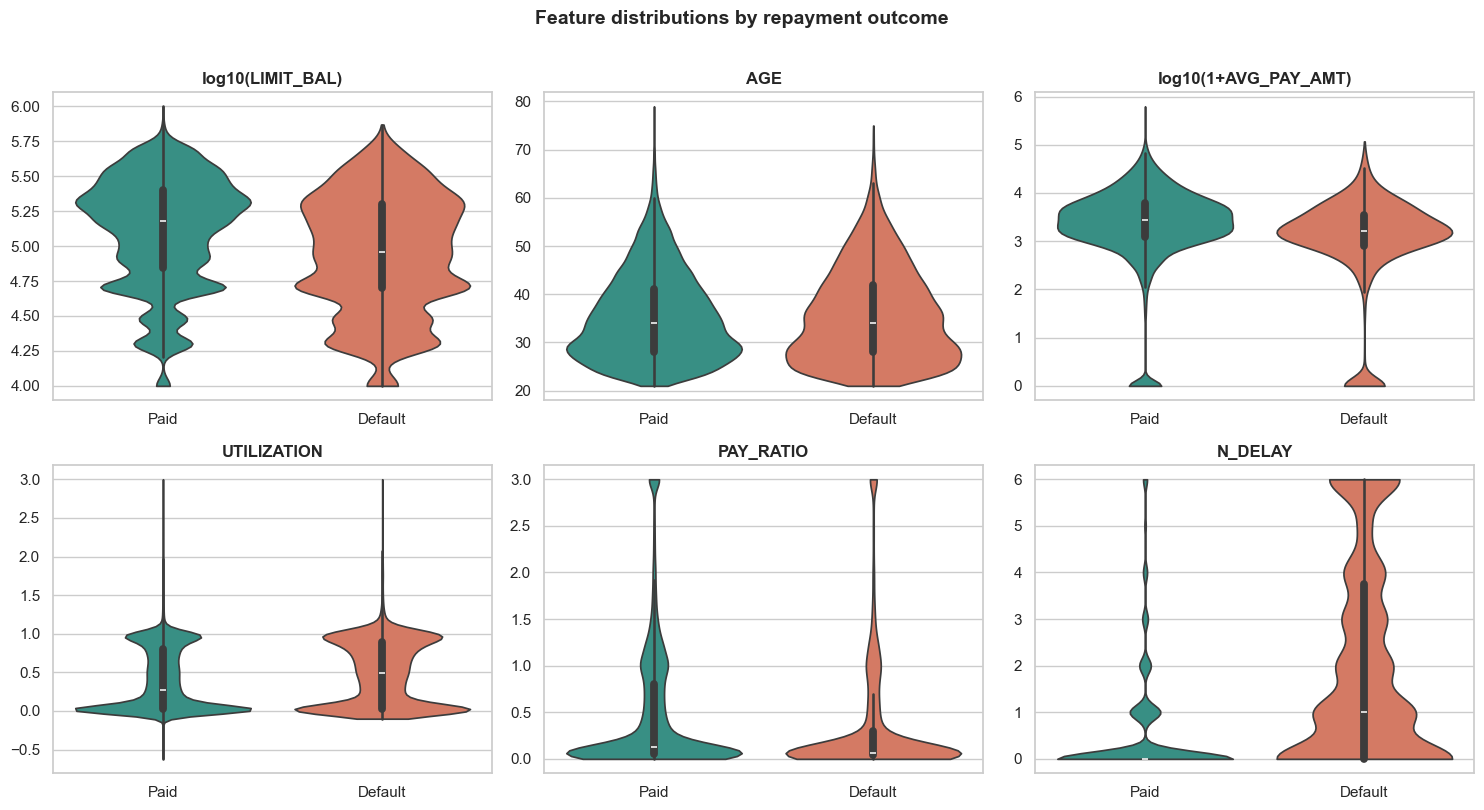

,feature,median (paid),median (default),p-value,rank-biserial effect
0,LIMIT_BAL,150000.000,90000.000,6.15e-190,0.236
1,AGE,34.000,34.000,4.04e-01,0.007
2,AVG_BILL,21493.500,19802.333,2.71e-06,0.038
3,AVG_PAY_AMT,2761.667,1614.750,7.66e-201,0.243
4,UTILIZATION,0.269,0.494,1.74e-36,0.101
5,PAY_RATIO,0.130,0.067,1.92e-125,0.191
6,N_DELAY,0.000,1.000,0.00e+00,0.452


In [18]:
# VIS 8 - Numeric features split by outcome (violin + box) and Mann-Whitney U tests
vis["log10(LIMIT_BAL)"] = np.log10(vis["LIMIT_BAL"]); vis["log10(1+AVG_PAY_AMT)"] = np.log10(1 + vis["AVG_PAY_AMT"])
cols = ["log10(LIMIT_BAL)", "AGE", "log10(1+AVG_PAY_AMT)", "UTILIZATION", "PAY_RATIO", "N_DELAY"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), cols):
    sns.violinplot(data=vis, x="Status", y=c, order=["Paid", "Default"], palette=PAL, inner="box", cut=0, ax=a)
    a.set(title=c, xlabel="", ylabel="")
plt.suptitle("Feature distributions by repayment outcome", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); save_fig("08_violin_by_outcome"); plt.show()
rows = []
for c in ["LIMIT_BAL", "AGE", "AVG_BILL", "AVG_PAY_AMT", "UTILIZATION", "PAY_RATIO", "N_DELAY"]:   # rank test: monotone transforms do not matter
    a_, b_ = df.loc[df.DEFAULT == 0, c], df.loc[df.DEFAULT == 1, c]
    u, pv = stats.mannwhitneyu(a_, b_)
    rows.append((c, round(a_.median(), 3), round(b_.median(), 3), f"{pv:.2e}", round(abs(1 - 2 * u / (len(a_) * len(b_))), 3)))
mw_tbl = pd.DataFrame(rows, columns=["feature", "median (paid)", "median (default)", "p-value", "rank-biserial effect"]); mw_tbl

**What it shows:** Violin + box plots of six numeric features split by outcome, with Mann-Whitney U tests (median, p-value and rank-biserial effect size) for seven features.

**Why I created it:** To see how the entire distribution - not just the mean - differs between customers who paid and those who defaulted.

**Insights:**
- **N_DELAY** separates the groups best (effect size 0.45): paid customers almost always have 0 late months, defaulters have a median of 1 and a long tail up to 6.
- Defaulters have **lower limits** (median NT$90,000 vs 150,000, effect 0.24), **repay less** (median average payment NT$1,615 vs 2,762, effect 0.24) and use **more of their limit** (utilization 0.49 vs 0.27).
- **AGE has no effect** (medians equal at 34, p = 0.40) and AVG_BILL only a very small one (0.04): how big the bill is matters less than how much of it is repaid and when.
- Several violins are bimodal (e.g. utilization has peaks near 0 and near 1), hinting at distinct customer groups.

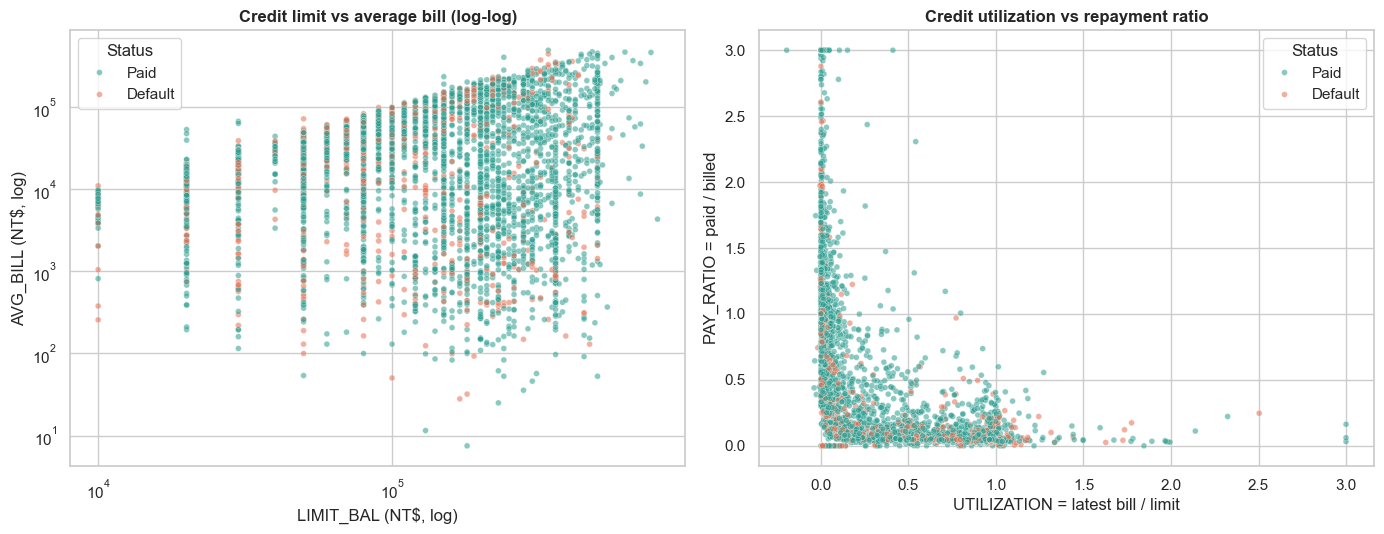

In [19]:
# VIS 9 - Scatterplot: credit limit vs average bill, coloured by outcome (sample of 4,000 for readability)
samp = vis[vis["AVG_BILL"] > 0].sample(4000, random_state=SEED)      # positive average bills only so a log axis can be used
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=samp, x="LIMIT_BAL", y="AVG_BILL", hue="Status", palette=PAL, alpha=.55, s=18, ax=ax[0])
ax[0].set(xscale="log", yscale="log", title="Credit limit vs average bill (log-log)", xlabel="LIMIT_BAL (NT$, log)", ylabel="AVG_BILL (NT$, log)")
sns.scatterplot(data=samp, x="UTILIZATION", y="PAY_RATIO", hue="Status", palette=PAL, alpha=.55, s=18, ax=ax[1])
ax[1].set(title="Credit utilization vs repayment ratio", xlabel="UTILIZATION = latest bill / limit", ylabel="PAY_RATIO = paid / billed")
plt.tight_layout(); save_fig("09_scatterplots"); plt.show()

**What it shows:** Left: credit limit vs average bill (both log axes). Right: credit utilization vs repayment ratio. Colour = outcome; random sample of 4,000 customers.

**Why I created it:** To inspect the relationship between two continuous variables and where defaulters sit.

**Insights:**
- The bill grows with the credit limit but is capped by it; vertical stripes are the round-number limits.
- Utilization and repayment ratio show a clear **L-shaped inverse relationship** (Spearman -0.6): customers who use little credit repay a large share, those who max out their limit repay almost nothing.
- Defaulters (orange) lean towards high utilization and low repayment but overlap heavily with paid customers, which warns that no single pair of variables will separate the classes cleanly.

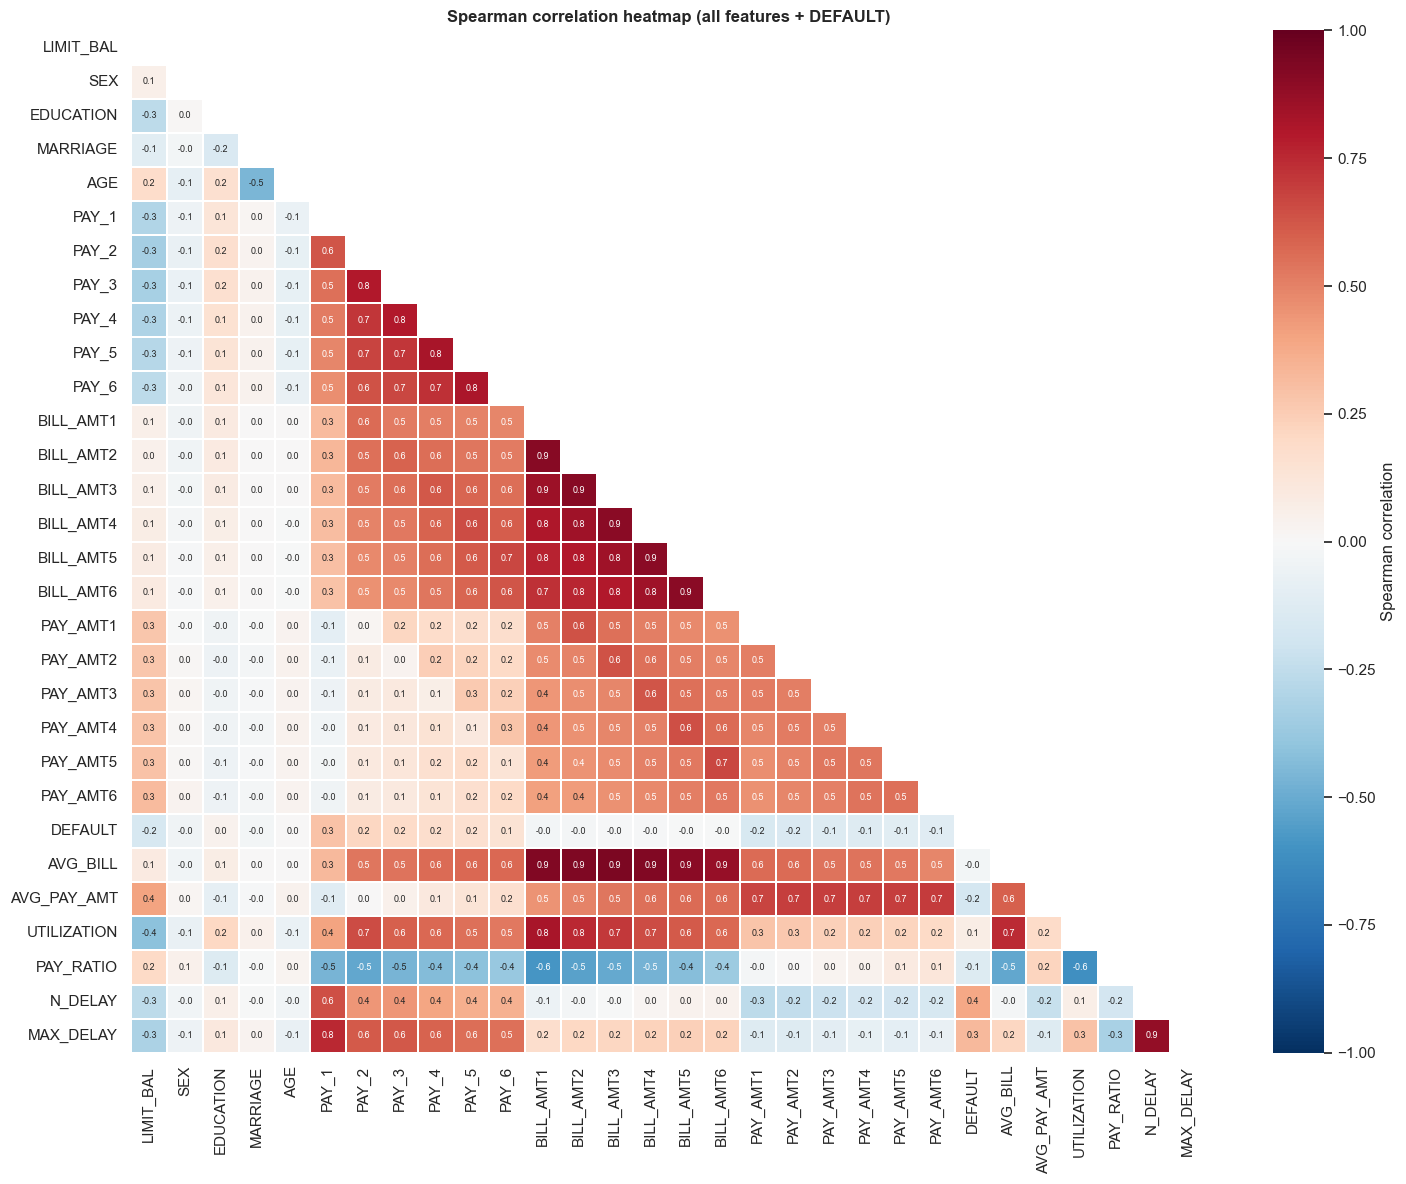

Correlation with DEFAULT (top 10 by |rho|):
N_DELAY        0.388
MAX_DELAY      0.321
PAY_1          0.292
PAY_2          0.217
PAY_3          0.195
AVG_PAY_AMT   -0.175
PAY_4          0.174
LIMIT_BAL     -0.170
PAY_AMT1      -0.161
PAY_5          0.159


In [20]:
# VIS 10 - Correlation heatmap (Spearman is robust to the skewed money columns)
num_cols = [c for c in df.columns if c not in ("AGE_GRP", "LIMIT_Q")]
corr = df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 6.5},
            linewidths=.3, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation heatmap (all features + DEFAULT)"); ax.grid(False)
plt.tight_layout(); save_fig("10_correlation_heatmap"); plt.show()
print("Correlation with DEFAULT (top 10 by |rho|):")
print(corr["DEFAULT"].drop("DEFAULT").reindex(corr["DEFAULT"].drop("DEFAULT").abs().sort_values(ascending=False).index).head(10).round(3).to_string())

**What it shows:** Spearman correlation matrix of all numeric features and the target (lower triangle).

**Why I created it:** Multivariate overview: which features move together and which relate to default. Spearman is used because the money columns are skewed.

**Insights:**
- **Strong multicollinearity:** the six BILL_AMT columns correlate 0.7-0.9 with each other, PAY_1..PAY_6 form a chain of 0.5-0.8 and AVG_BILL is almost the same variable as the bills (0.9).
- Correlation with DEFAULT is highest for **N_DELAY (0.39), MAX_DELAY (0.32), PAY_1 (0.29), PAY_2 (0.22)**; negative for AVG_PAY_AMT (-0.18), LIMIT_BAL (-0.17) and PAY_AMT1 (-0.16).
- The bill amounts have essentially **zero** correlation with default (about 0.0), even though they correlate strongly with everything else.
- Other structure: UTILIZATION vs PAY_RATIO = -0.6, MARRIAGE vs AGE = -0.5, EDUCATION vs LIMIT_BAL = -0.3. The collinearity is a reason to prefer regularised models and to interpret feature importance carefully.

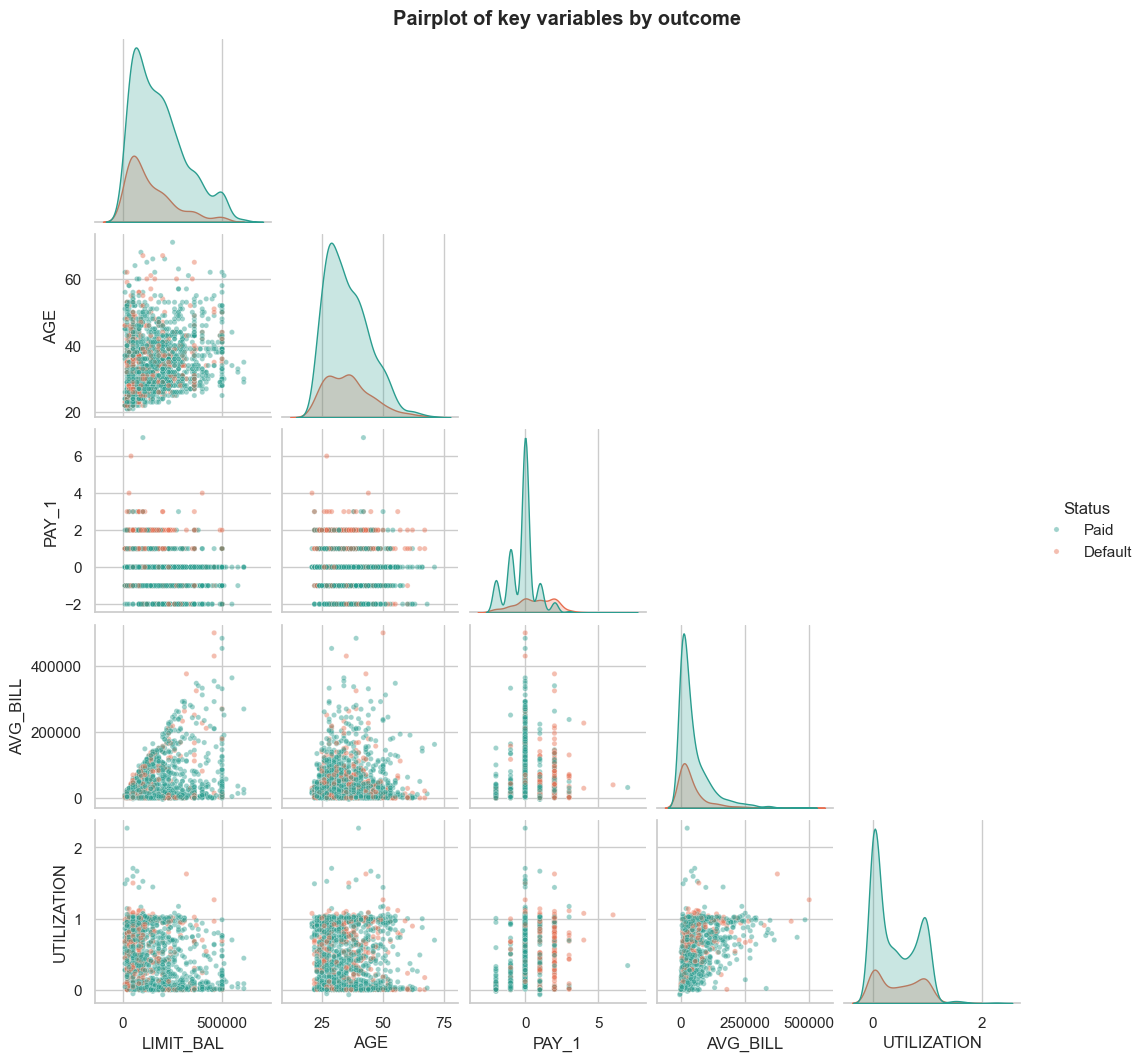

In [21]:
# VIS 11 - Pairplot of the most informative variables (1,500-row sample)
cols = ["LIMIT_BAL", "AGE", "PAY_1", "AVG_BILL", "UTILIZATION", "Status"]
g = sns.pairplot(vis.sample(1500, random_state=SEED)[cols], hue="Status", palette=PAL, corner=True, plot_kws={"alpha": .45, "s": 14},
                 diag_kind="kde", height=2.1)
g.figure.suptitle("Pairplot of key variables by outcome", y=1.01, fontweight="bold")
g.savefig(f"{FIG_DIR}/11_pairplot.png", dpi=130, bbox_inches="tight"); plt.show()

**What it shows:** Scatter matrix and KDE of credit limit, age, latest repayment status, average bill and utilization, coloured by outcome.

**Why I created it:** A compact multivariate view of how the most informative variables relate to each other and to the outcome.

**Insights:**
- In the PAY_1 panels the orange (default) points concentrate at PAY_1 = 1, 2, 3, while 0, -1 and -2 are mostly teal, i.e. PAY_1 separates the classes better than any other variable shown.
- AVG_BILL fans out with LIMIT_BAL (a higher limit allows higher bills) but the two colours overlap almost completely - consistent with bills being weak predictors.
- The KDE of UTILIZATION is bimodal, with peaks near 0 (unused card) and near 1 (limit maxed out).
- AGE and LIMIT_BAL show heavy overlap between the classes, so these are only weak predictors on their own.

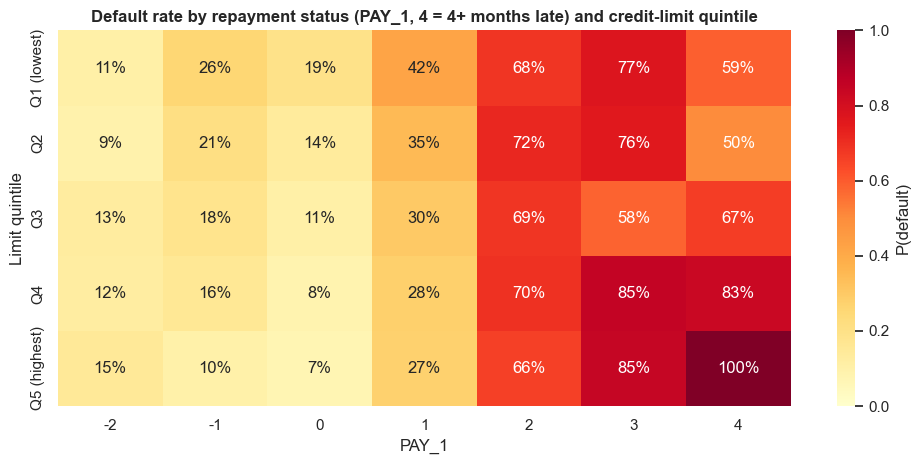

Smallest cell size: 9


In [22]:
# VIS 12 - Multivariate: default rate by latest repayment status x credit-limit quintile
tmp = df.assign(PAY_1c=df["PAY_1"].clip(upper=4))
piv = tmp.pivot_table(index="LIMIT_Q", columns="PAY_1c", values="DEFAULT", aggfunc="mean")
cnt = tmp.pivot_table(index="LIMIT_Q", columns="PAY_1c", values="DEFAULT", aggfunc="size")
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(piv, annot=True, fmt=".0%", cmap="YlOrRd", vmin=0, vmax=1, cbar_kws={"label": "P(default)"}, ax=ax)
ax.set(title="Default rate by repayment status (PAY_1, 4 = 4+ months late) and credit-limit quintile", xlabel="PAY_1", ylabel="Limit quintile")
plt.tight_layout(); save_fig("12_multivariate_heatmap"); plt.show()
print("Smallest cell size:", int(cnt.min().min()))

**What it shows:** Default rate for each combination of repayment status (columns) and credit-limit quintile (rows).

**Why I created it:** To check an interaction: does the limit still matter once repayment behaviour is known?

**Insights:**
- **Repayment status dominates:** default rates are 7-26 % for PAY_1 <= 0, 27-42 % one month late, and 50-100 % from two months late onwards, in every limit quintile.
- Among customers in good standing (PAY_1 = 0) the limit still matters: default falls from 19 % (lowest quintile) to 7 % (highest).
- For seriously late customers the pattern reverses: in the top two limit quintiles those 3+ months late default 83-100 % (small cells, minimum n = 9, so treat with caution).
- Counter-intuitive: 'paid duly' (-1) has a *higher* default rate (10-26 %) than 'revolving credit' (0, 7-19 %); customers who pay in full may include more volatile or low-balance accounts.

## 7. Interactive Visualization (Interact)
A Plotly scatter that lets the reader hover, zoom and filter by outcome. It is saved as a standalone HTML file in `figures/`.

In [23]:
fig = px.scatter(vis.sample(5000, random_state=SEED), x="LIMIT_BAL", y="AVG_BILL", color="Status", color_discrete_map=PAL,
                 size="N_DELAY", size_max=14, opacity=.6, log_x=True,
                 hover_data=["AGE", "PAY_1", "UTILIZATION", "EDUCATION"],
                 title="Interactive: credit limit vs average bill (bubble size = months paid late)")
fig.update_layout(template="plotly_white", xaxis_title="LIMIT_BAL (NT$, log)", yaxis_title="AVG_BILL (NT$)")
fig.write_html(f"{FIG_DIR}/13_interactive_scatter.html", include_plotlyjs="cdn")
print("Saved interactive chart ->", f"{FIG_DIR}/13_interactive_scatter.html (open in a browser)")

Saved interactive chart -> ../figures/13_interactive_scatter.html (open in a browser)


The interactive chart (`figures/13_interactive_scatter.html`) allows hover, zoom and toggling of paid/default points, completing the *Interact* stage of the visualization pipeline.

## 8. Preprocessing for Modelling
* **Signed-log transform** for money columns (tames skew and outliers without deleting customers).
* **One-hot encoding** for the nominal columns SEX, EDUCATION, MARRIAGE.
* **Standardization** (z-score) for numeric columns, **fitted on the training set only** to avoid leakage.
* **Stratified split 70 / 15 / 15** into train / validation / test.

In [24]:
TARGET = "DEFAULT"
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
money_cols = bill + pay_amt + ["LIMIT_BAL", "AVG_BILL", "AVG_PAY_AMT"]
num_cols = [c for c in df.columns if c not in cat_cols + [TARGET, "AGE_GRP", "LIMIT_Q"]]

X = df[cat_cols + num_cols].copy()
y = df[TARGET].values
X[money_cols] = np.sign(X[money_cols]) * np.log1p(np.abs(X[money_cols]))       # signed log1p

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

pre = ColumnTransformer([("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
                         ("num", StandardScaler(), num_cols)])
Xtr = pre.fit_transform(X_tr); Xva = pre.transform(X_va); Xte = pre.transform(X_te)   # fit on TRAIN only
feat_names = [n.split("__")[1] for n in pre.get_feature_names_out()]
print(f"Train {Xtr.shape} | Val {Xva.shape} | Test {Xte.shape}  ->  {len(feat_names)} model input features")
print("Default rate  train/val/test: %.3f / %.3f / %.3f" % (y_tr.mean(), y_va.mean(), y_te.mean()))
print(f"Mean |skew| of money columns: before = {df[money_cols].skew().abs().mean():.2f}, after log+scale = {pd.DataFrame(Xtr, columns=feat_names)[money_cols].skew().abs().mean():.2f}")

Train (20975, 32) | Val (4495, 32) | Test (4495, 32)  ->  32 model input features
Default rate  train/val/test: 0.221 / 0.221 / 0.221
Mean |skew| of money columns: before = 8.82, after log+scale = 1.50


**Result:** 20,975 / 4,495 / 4,495 customers for train / validation / test, each with the same 22.1 % default rate (stratified). The one-hot encoding turns the 29 input features into **32 model inputs**. The signed log transform reduces the mean absolute skew of the money columns from 8.8 to 1.5. Scalers and encoders were fitted on the training set only, so there is no data leakage.

## 9. Deep Learning Model – Multi-Layer Perceptron (PyTorch)
Architecture: `Input -> [Linear -> BatchNorm -> ReLU -> Dropout] x L -> Linear(1) -> sigmoid`, trained with binary cross-entropy and the Adam optimizer, early stopping on validation loss. A small grid search tunes the layer sizes, dropout and learning rate (basic hyperparameter tuning).

In [25]:
class MLP(nn.Module):
    """Fully connected network for tabular binary classification."""
    def __init__(self, in_dim, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)          # raw logits

def to_t(a, dtype=torch.float32): return torch.tensor(np.asarray(a), dtype=dtype, device=DEVICE)
Xtr_t, Xva_t, Xte_t = to_t(Xtr), to_t(Xva), to_t(Xte)
ytr_t, yva_t = to_t(y_tr), to_t(y_va)

@torch.no_grad()
def predict_proba(model, X_t):
    model.eval(); return torch.sigmoid(model(X_t)).cpu().numpy()

def train_model(hidden, dropout, lr, weight_decay=1e-4, epochs=40, batch=256, patience=6):
    """Train one MLP; returns (best model, history dict). Early stopping on validation loss."""
    torch.manual_seed(SEED)
    model = MLP(Xtr.shape[1], hidden, dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch, shuffle=True, generator=g)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "val_auc"]}
    best, best_state, wait = np.inf, None, 0
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in loader:
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        with torch.no_grad():
            model.eval()
            ltr = crit(model(Xtr_t), ytr_t).item(); lva = crit(model(Xva_t), yva_t).item()
        ptr, pva = predict_proba(model, Xtr_t), predict_proba(model, Xva_t)
        hist["train_loss"].append(ltr); hist["val_loss"].append(lva)
        hist["train_acc"].append(accuracy_score(y_tr, ptr > .5)); hist["val_acc"].append(accuracy_score(y_va, pva > .5))
        hist["val_auc"].append(roc_auc_score(y_va, pva))
        if lva < best - 1e-4:
            best, wait = lva, 0; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return model, hist

In [26]:
# ---------- Hyperparameter tuning: 3 architectures x 2 dropouts x 2 learning rates = 12 runs ----------
import itertools, time
grid = list(itertools.product([(64, 32), (128, 64), (128, 64, 32)], [0.2, 0.4], [1e-3, 3e-3]))
results, models, hists = [], {}, {}
t0 = time.time()
for hidden, dr, lr in grid:
    m_, h_ = train_model(hidden, dr, lr)
    key = (hidden, dr, lr); models[key] = m_; hists[key] = h_
    best_ep = int(np.argmin(h_["val_loss"]))
    results.append({"hidden": str(hidden), "dropout": dr, "lr": lr, "epochs_run": len(h_["val_loss"]),
                    "best_epoch": best_ep + 1, "val_loss": min(h_["val_loss"]), "val_auc": h_["val_auc"][best_ep]})
tune = pd.DataFrame(results).sort_values("val_auc", ascending=False).reset_index(drop=True)
print(f"Tuning finished in {time.time()-t0:.0f}s")
tune.round(4)

Tuning finished in 133s


,hidden,dropout,lr,epochs_run,best_epoch,val_loss,val_auc
0,"(128, 64, 32)",0.2,0.001,23,17,0.4273,0.7811
1,"(64, 32)",0.2,0.001,24,18,0.4270,0.7809
2,"(128, 64, 32)",0.4,0.003,24,18,0.4276,0.7807
3,"(128, 64, 32)",0.2,0.003,22,16,0.4278,0.7805
4,"(64, 32)",0.4,0.001,40,39,0.4269,0.7803
5,"(128, 64, 32)",0.4,0.001,24,18,0.4290,0.7800
6,"(64, 32)",0.4,0.003,30,24,0.4275,0.7800
7,"(128, 64)",0.2,0.003,23,17,0.4282,0.7796
8,"(64, 32)",0.2,0.003,19,13,0.4280,0.7794
9,"(128, 64)",0.4,0.003,23,17,0.4288,0.7793


**Result:** the 12 configurations reach validation AUC between 0.777 and 0.781, a spread of only 0.004. Architecture, dropout and learning rate matter very little - the performance ceiling comes from the information in the data, not from the network design. The best configuration (128-64-32 hidden units, dropout 0.2, lr 0.001) was selected on **validation AUC**, never on the test set.

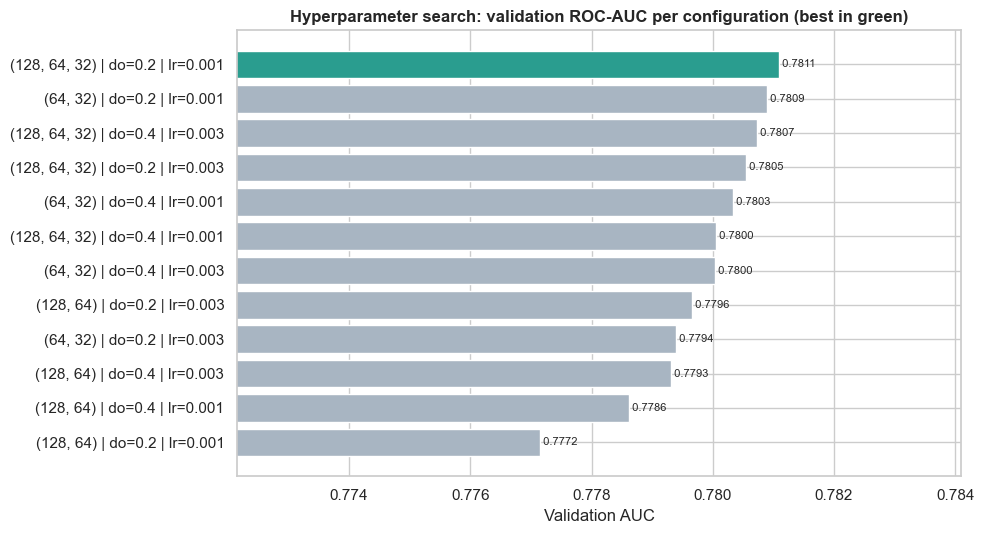

Best configuration -> hidden: (128, 64, 32) | dropout: 0.2 | lr: 0.001
Trainable parameters: 15041


In [27]:
# VIS 14 - Hyperparameter tuning results (validation AUC)
t = tune.copy(); t["config"] = t["hidden"] + " | do=" + t["dropout"].astype(str) + " | lr=" + t["lr"].astype(str)
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [C_OK if i == 0 else "#a8b5c2" for i in range(len(t))]
ax.barh(t["config"][::-1], t["val_auc"][::-1], color=colors[::-1])
ax.set_xlim(t["val_auc"].min() - 0.005, t["val_auc"].max() + 0.003)
for i, v_ in enumerate(t["val_auc"][::-1]): ax.text(v_, i, f" {v_:.4f}", va="center", fontsize=8)
ax.set(title="Hyperparameter search: validation ROC-AUC per configuration (best in green)", xlabel="Validation AUC")
plt.tight_layout(); save_fig("14_hyperparameter_tuning"); plt.show()
best_cfg = (eval(tune.loc[0, "hidden"]), tune.loc[0, "dropout"], tune.loc[0, "lr"])
model, hist = models[best_cfg], hists[best_cfg]
print("Best configuration -> hidden:", best_cfg[0], "| dropout:", best_cfg[1], "| lr:", best_cfg[2])
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

**What it shows:** Validation AUC of every hyperparameter combination (best in green).

**Why I created it:** To document the tuning and to show how sensitive the model is to the chosen hyperparameters.

**Insights:**
- All 12 bars are within 0.004 AUC of each other: the model is robust to hyperparameter choices.
- The selected network has 3 hidden layers (128-64-32), dropout 0.2, learning rate 0.001 and 15,041 trainable parameters.

## 10. Model Evaluation & Result Visualization

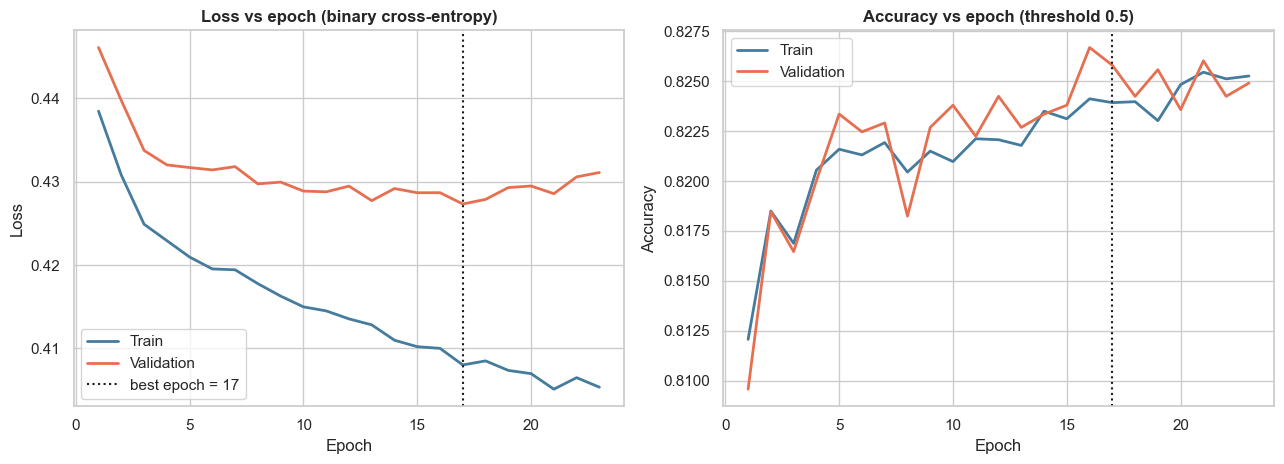

In [28]:
# VIS 15 - Learning curves of the best model (loss and accuracy vs epoch)
ep = np.arange(1, len(hist["train_loss"]) + 1); be = int(np.argmin(hist["val_loss"])) + 1
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(ep, hist["train_loss"], label="Train", color="#457b9d", lw=2); ax[0].plot(ep, hist["val_loss"], label="Validation", color=C_DEF, lw=2)
ax[0].axvline(be, color="k", ls=":", label=f"best epoch = {be}"); ax[0].set(title="Loss vs epoch (binary cross-entropy)", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].plot(ep, hist["train_acc"], label="Train", color="#457b9d", lw=2); ax[1].plot(ep, hist["val_acc"], label="Validation", color=C_DEF, lw=2)
ax[1].axvline(be, color="k", ls=":"); ax[1].set(title="Accuracy vs epoch (threshold 0.5)", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); save_fig("15_learning_curves"); plt.show()

**What it shows:** Training and validation loss (left) and accuracy (right) after every epoch of the selected model.

**Why I created it:** To diagnose under/over-fitting and justify early stopping.

**Insights:**
- Training loss keeps falling (to ~0.405) while validation loss flattens at ~0.427 around epoch 17 and then drifts upward: the typical start of **over-fitting**. Early stopping restored the weights of epoch 17.
- The train-validation gap is small (~0.02), so the model generalises reasonably; there is no sign of severe over-fitting.
- Accuracy at a 0.5 threshold plateaus at about 82-83 % for both sets. That is only ~4-5 points above the 77.9 % majority-class baseline, which is why AUC and recall are the more informative metrics here.

In [29]:
# Baselines on the same features, to judge whether the MLP is actually worthwhile
lr_m = LogisticRegression(max_iter=2000).fit(Xtr, y_tr)
rf_m = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(Xtr, y_tr)
p_mlp_va, p_mlp = predict_proba(model, Xva_t), predict_proba(model, Xte_t)
p_lr, p_rf = lr_m.predict_proba(Xte)[:, 1], rf_m.predict_proba(Xte)[:, 1]

# Decision threshold: the 0.5 default is poor for a 22 % minority class -> pick the F1-optimal one on VALIDATION data
prec, rec, thr = precision_recall_curve(y_va, p_mlp_va)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THR = float(thr[np.argmax(f1s)]); print(f"Chosen decision threshold (max validation F1): {THR:.3f}")

def metrics(name, p, thr):
    yhat = (p >= thr).astype(int)
    return {"model": name, "accuracy": accuracy_score(y_te, yhat), "precision": precision_score(y_te, yhat),
            "recall": recall_score(y_te, yhat), "f1": f1_score(y_te, yhat), "roc_auc": roc_auc_score(y_te, p),
            "pr_auc": average_precision_score(y_te, p)}
def best_thr(p_val):
    pr, rc, th = precision_recall_curve(y_va, p_val); f = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12); return th[np.argmax(f)]
res = pd.DataFrame([metrics("MLP (PyTorch)", p_mlp, THR),
                    metrics("Logistic Regression", p_lr, best_thr(lr_m.predict_proba(Xva)[:, 1])),
                    metrics("Random Forest", p_rf, best_thr(rf_m.predict_proba(Xva)[:, 1])),
                    metrics("MLP @ threshold 0.5", p_mlp, 0.5)]).round(4)
res.to_csv(f"{REPORT_DIR}/test_metrics.csv", index=False)
print("TEST-SET RESULTS (threshold tuned on validation data)"); res

Chosen decision threshold (max validation F1): 0.327
TEST-SET RESULTS (threshold tuned on validation data)


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,MLP (PyTorch),0.7918,0.5282,0.5463,0.5371,0.7850,0.5558
1,Logistic Regression,0.7798,0.5018,0.5744,0.5356,0.7658,0.5256
2,Random Forest,0.7989,0.5493,0.5040,0.5257,0.7793,0.5600
3,MLP @ threshold 0.5,0.8191,0.6625,0.3712,0.4758,0.7850,0.5558


**Result:** on the untouched test set the MLP reaches **ROC-AUC 0.785**, slightly above Random Forest (0.779) and Logistic Regression (0.766). The threshold chosen on validation data (0.327) trades some accuracy for recall: at the default 0.5 the MLP would be more 'accurate' (81.9 %) but would catch only 37 % of defaulters (recall), against 54.6 % at the tuned threshold. In a bank, missing a defaulter usually costs more than a false alarm, so the tuned threshold is the more sensible operating point.

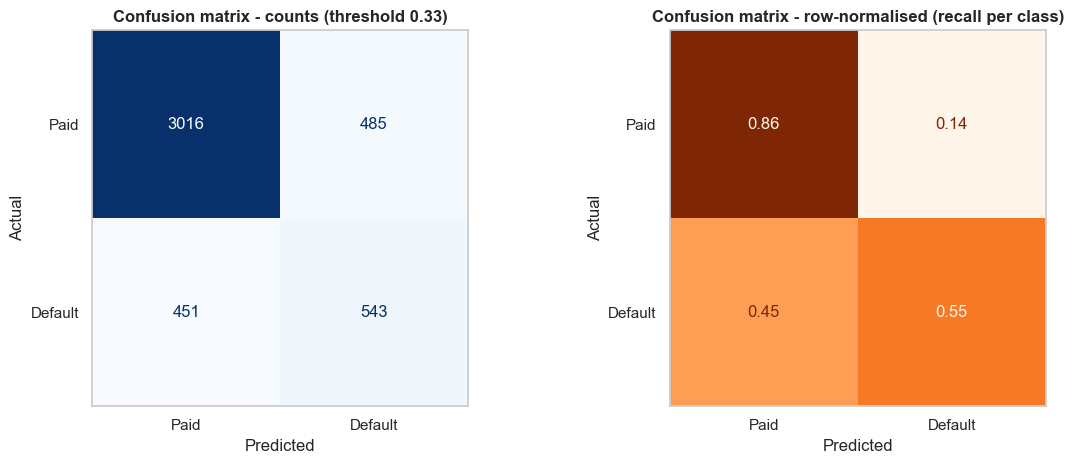

              precision    recall  f1-score   support

        Paid      0.870     0.861     0.866      3501
     Default      0.528     0.546     0.537       994

    accuracy                          0.792      4495
   macro avg      0.699     0.704     0.701      4495
weighted avg      0.794     0.792     0.793      4495



In [30]:
# VIS 16 - Confusion matrix of the MLP on the unseen test set
yhat = (p_mlp >= THR).astype(int)
cm = confusion_matrix(y_te, yhat)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm, display_labels=["Paid", "Default"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title(f"Confusion matrix - counts (threshold {THR:.2f})")
ConfusionMatrixDisplay(confusion_matrix(y_te, yhat, normalize="true"), display_labels=["Paid", "Default"]).plot(ax=ax[1], cmap="Oranges", colorbar=False, values_format=".2f")
ax[1].set_title("Confusion matrix - row-normalised (recall per class)")
for a in ax: a.set(xlabel="Predicted", ylabel="Actual"); a.grid(False)
plt.tight_layout(); save_fig("16_confusion_matrix"); plt.show()
print(classification_report(y_te, yhat, target_names=["Paid", "Default"], digits=3))

**What it shows:** Test-set confusion matrix of the MLP, as counts (left) and row-normalised percentages (right).

**Why I created it:** To see the types of mistakes made, not just the overall accuracy.

**Insights:**
- Of 994 real defaulters the model catches **543 (recall 55 %)** and misses 451; of 3,501 good customers it correctly clears **3,016 (86 %)** and wrongly flags 485.
- Precision for defaults is 53 % (543 of 1,028 flagged customers really default), F1 = 0.54; overall accuracy 79.2 %.
- Roughly half of the defaulters cannot be identified from the data, which is consistent with the overlapping score distributions below.

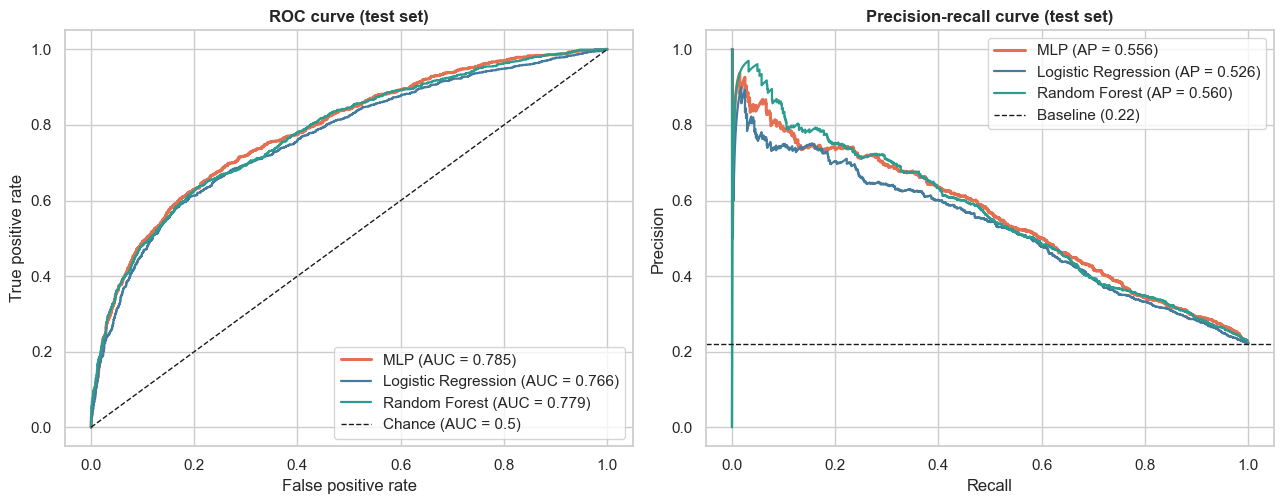

In [31]:
# VIS 17 - ROC curves (with AUC) and precision-recall curves, MLP vs baselines
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for name, p, c in [("MLP", p_mlp, C_DEF), ("Logistic Regression", p_lr, "#457b9d"), ("Random Forest", p_rf, "#2a9d8f")]:
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, color=c, lw=2.2 if name == "MLP" else 1.6, label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")
    pr_, rc_, _ = precision_recall_curve(y_te, p); ax[1].plot(rc_, pr_, color=c, lw=2.2 if name == "MLP" else 1.6, label=f"{name} (AP = {average_precision_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.5)")
ax[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(loc="lower right")
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=1, label=f"Baseline ({y_te.mean():.2f})")
ax[1].set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); save_fig("17_roc_pr_curves"); plt.show()

**What it shows:** ROC curves with AUC (left) and precision-recall curves with average precision (right) for the MLP, Logistic Regression and Random Forest on the test set.

**Why I created it:** ROC/AUC measure ranking quality independent of any threshold; the PR curve is more informative for an imbalanced target.

**Insights:**
- **AUC = 0.785 for the MLP** (0.5 = random, 1 = perfect): a randomly chosen defaulter receives a higher risk score than a randomly chosen payer 78.5 % of the time.
- The three curves almost coincide; the MLP is marginally better than Logistic Regression (0.766) and level with Random Forest (0.779) within noise. A deep model brings **little gain over simple models** on this tabular dataset.
- In the PR plot all models are far above the 0.22 baseline, but precision drops quickly as recall increases: catching most defaulters means many false alarms.

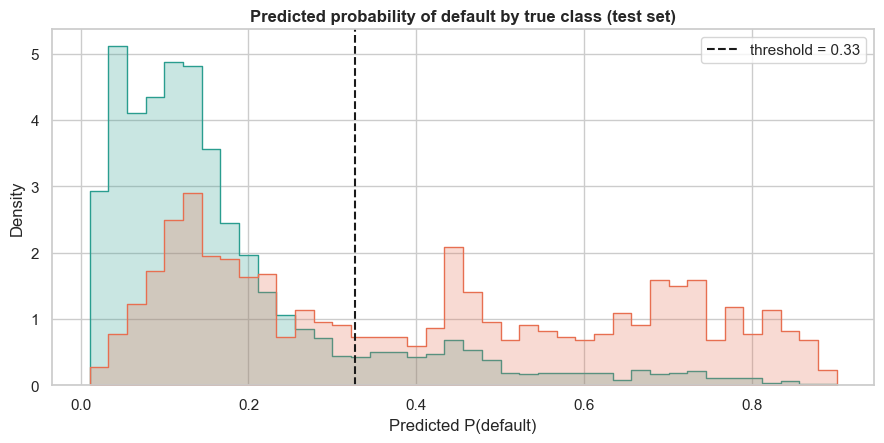

In [32]:
# VIS 18 - Distribution of predicted default probabilities (how well the model separates the classes)
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.histplot(x=p_mlp, hue=np.where(y_te == 1, "Default", "Paid"), palette=PAL, bins=40, stat="density", common_norm=False, element="step", ax=ax)
ax.axvline(THR, color="k", ls="--", label=f"threshold = {THR:.2f}"); ax.legend()
ax.set(title="Predicted probability of default by true class (test set)", xlabel="Predicted P(default)", ylabel="Density")
plt.tight_layout(); save_fig("18_score_distribution"); plt.show()

**What it shows:** Histogram of the predicted default probability for each true class on the test set, with the decision threshold.

**Why I created it:** To understand *why* the model performs as it does by looking at how well the scores separate the classes.

**Insights:**
- Paid customers (teal) are concentrated at low predicted probabilities (mostly 0.03-0.2); defaulters (orange) form two groups: a large one at 0.6-0.8+ that the model identifies confidently, and another that sits in the same low-probability range as good customers. That second group looks like reliable payers in the data (for example, a sudden income shock) and cannot be detected - this overlap is the cause of the AUC ceiling at about 0.78.

## 11. Feature Analysis & Feature Importance

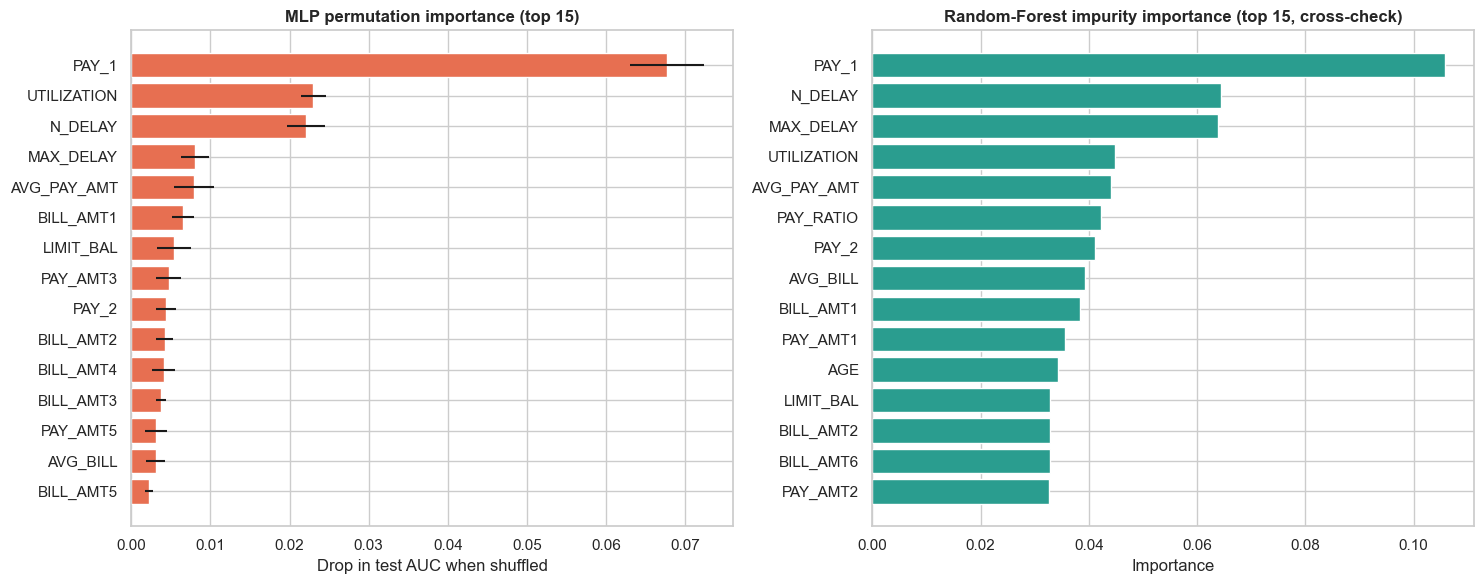

,feature,mlp_auc_drop,mlp_std,rf_importance
8,PAY_1,0.0677,0.0047,0.1059
28,UTILIZATION,0.0230,0.0016,0.0448
30,N_DELAY,0.0221,0.0024,0.0645
31,MAX_DELAY,0.0080,0.0018,0.0638
27,AVG_PAY_AMT,0.0079,0.0025,0.0442
14,BILL_AMT1,0.0065,0.0014,0.0383
6,LIMIT_BAL,0.0054,0.0021,0.0328
22,PAY_AMT3,0.0047,0.0016,0.0314
9,PAY_2,0.0044,0.0013,0.0412
15,BILL_AMT2,0.0042,0.0011,0.0328


In [33]:
# Permutation importance of the MLP: drop in test AUC when one feature is shuffled (5 repeats)
rng = np.random.default_rng(SEED)
base = roc_auc_score(y_te, p_mlp); imp = np.zeros((len(feat_names), 5))
for j in range(len(feat_names)):
    for r in range(5):
        Xp = Xte.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        imp[j, r] = base - roc_auc_score(y_te, predict_proba(model, to_t(Xp)))
imp_df = pd.DataFrame({"feature": feat_names, "mlp_auc_drop": imp.mean(1), "mlp_std": imp.std(1), "rf_importance": rf_m.feature_importances_})
top = imp_df.sort_values("mlp_auc_drop", ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(top["feature"][::-1], top["mlp_auc_drop"][::-1], xerr=top["mlp_std"][::-1], color="#e76f51")
ax[0].set(title="MLP permutation importance (top 15)", xlabel="Drop in test AUC when shuffled")
top2 = imp_df.sort_values("rf_importance", ascending=False).head(15)
ax[1].barh(top2["feature"][::-1], top2["rf_importance"][::-1], color="#2a9d8f")
ax[1].set(title="Random-Forest impurity importance (top 15, cross-check)", xlabel="Importance")
plt.tight_layout(); save_fig("19_feature_importance"); plt.show()
imp_df.sort_values("mlp_auc_drop", ascending=False).head(10).round(4)

**What it shows:** Left: permutation importance of the MLP - how much the test AUC drops when one feature is randomly shuffled (mean +/- std over 5 repeats). Right: Random-Forest impurity importance as a cross-check.

**Why I created it:** Feature analysis: which inputs the model really relies on.

**Insights:**
- **PAY_1 (latest repayment status) is the most important feature in both models** - shuffling it costs 0.068 AUC, about three times more than any other feature.
- Next come UTILIZATION (0.023), N_DELAY (0.022), MAX_DELAY and AVG_PAY_AMT (0.008 each), BILL_AMT1 and LIMIT_BAL: the **engineered behavioural features** are among the top predictors, validating the feature engineering.
- Demographics (SEX, EDUCATION, MARRIAGE, AGE) have almost no importance, in line with the weak Cramer's V values found in EDA.
- Caveat: correlated features (PAY_1..6, BILL_AMT1..6) share credit, so each individually looks less important than the group does.

## 12. Summary of Key Numbers

In [34]:
summary_dict = {
    "rows_after_cleaning": int(len(df)), "n_features_raw": 23, "n_features_model": len(feat_names), "duplicates_removed": int(dups),
    "default_rate": float(df["DEFAULT"].mean()), "best_config": {"hidden": list(best_cfg[0]), "dropout": best_cfg[1], "lr": best_cfg[2]},
    "best_epoch": int(np.argmin(hist["val_loss"]) + 1), "epochs_run": len(hist["val_loss"]), "threshold": THR,
    "params": int(sum(p.numel() for p in model.parameters())),
    "test": res.set_index("model").to_dict(orient="index"),
}
json.dump(summary_dict, open(f"{REPORT_DIR}/summary_numbers.json", "w"), indent=2)
print(json.dumps(summary_dict, indent=2))

{
  "rows_after_cleaning": 29965,
  "n_features_raw": 23,
  "n_features_model": 32,
  "duplicates_removed": 35,
  "default_rate": 0.22125813449023862,
  "best_config": {
    "hidden": [
      128,
      64,
      32
    ],
    "dropout": 0.2,
    "lr": 0.001
  },
  "best_epoch": 17,
  "epochs_run": 23,
  "threshold": 0.32740098237991333,
  "params": 15041,
  "test": {
    "MLP (PyTorch)": {
      "accuracy": 0.7918,
      "precision": 0.5282,
      "recall": 0.5463,
      "f1": 0.5371,
      "roc_auc": 0.785,
      "pr_auc": 0.5558
    },
    "Logistic Regression": {
      "accuracy": 0.7798,
      "precision": 0.5018,
      "recall": 0.5744,
      "f1": 0.5356,
      "roc_auc": 0.7658,
      "pr_auc": 0.5256
    },
    "Random Forest": {
      "accuracy": 0.7989,
      "precision": 0.5493,
      "recall": 0.504,
      "f1": 0.5257,
      "roc_auc": 0.7793,
      "pr_auc": 0.56
    },
    "MLP @ threshold 0.5": {
      "accuracy": 0.8191,
      "precision": 0.6625,
      "recall": 0.37

## 13. Conclusion & Future Scope

**What we learned about the data**
- 30,000 credit-card customers (23 raw features, 29 after feature engineering); 22.1 % default next month - an imbalanced problem.
- Cleaning found no missing values but 35 duplicates, undocumented category codes and heavy right-skew/outliers in every money column.
- AGE follows a Gamma-like distribution, LIMIT_BAL is approximately log-normal, and the number of late months is over-dispersed (a mixture of reliable and chronic late payers).

**Key patterns**
- *Payment behaviour* beats demographics: default rises from ~13 % (on time) to ~69 % (two months late). N_DELAY, PAY_1, utilization, repayment ratio and credit limit are the main signals; age, sex, marital status and the bill amounts matter little.
- Higher limits go with lower default; utilization and repayment ratio are inversely related.

**Model performance** (PyTorch MLP, 128-64-32, test set): ROC-AUC **0.785**, average precision 0.556, accuracy 79.2 %, recall 54.6 %, precision 52.8 %, F1 0.537. It is slightly better than Logistic Regression (AUC 0.766) and level with Random Forest (0.779).

**Challenges**: class imbalance (accuracy misleading -> threshold tuning on validation data), multicollinearity, undocumented codes, skewed amounts, and a performance ceiling caused by overlapping classes.

**Limitations**: single time window (Taiwan, 2005), no income/employment/macro-economic data, the model only reaches ~55 % recall at ~53 % precision, and the threshold would have to be set by the bank's cost of a missed default versus a false alarm.

**Future scope**
- Cost-sensitive learning / class weights, SMOTE, or focal loss; calibration of probabilities.
- Gradient-boosting models (XGBoost/LightGBM) and an ensemble with the MLP; richer tuning with Optuna.
- More features: income, employment, transaction categories, month-on-month trends, macro-economic indicators; sequence models (LSTM/Transformer) on the 6-month history.
- Explainability (SHAP) for regulatory transparency, fairness checks across gender/age, and a monitored deployment.

*Key numbers of this run are saved in `report/summary_numbers.json` and `report/test_metrics.csv`.*